# PYTHON İLE ZAMAN SERİLERİ ANALİZİ ÖDEV RAPORU
## Şekil 3.1: Güney Yarımküre Aylık Sıcaklık Volatilitesi Serisi Uygulaması

* **Ad-Soyad:** Hazarali Zereyak  
* **Okul Numarası:** 2022140452  
* **GitHub Linki:** [https://github.com/hazarrzz](https://github.com/hazarrzz)  

---

**Kaynak:** *Applied Time Series Analysis and Forecasting with Python* (PDF s. 83, Örnek 3.1, Şekil 3.1)  
**Veri Dosyası:** `Southtemperature.txt` (Ocak 1850 – Aralık 2007 arası 158 yıl $\times$ 12 ay = $T = 1896$ aylık kesikli gözlem)

**Uygulama Adımları:**
1. Zaman Serisi Grafiği (Şekil 3.1)
2. Gecikme (Lag) İşlemcisi
3. Fark (Difference) İşlemcisi
4. ACF ve PACF Grafikleri
5. Durağanlığın İncelenmesi

---
## 1. Zaman Serisi Grafiği (Şekil 3.1)
### 1.1 Python Kodu ve Çıktısı

Veri Tipi           : <class 'pandas.core.series.Series'>
Gözlem Sayısı (T)   : 1896 (Ocak 1850 - Aralık 2007, Aylık Kesikli Zaman Serisi)
Örneklem Ortalaması : -0.221604 °C
Standart Sapma (s)  : 0.270654 °C
Varyans (gamma_0)   : 0.073254
Min / Medyan / Maks : -0.986 °C / -0.265 °C / 0.618 °C

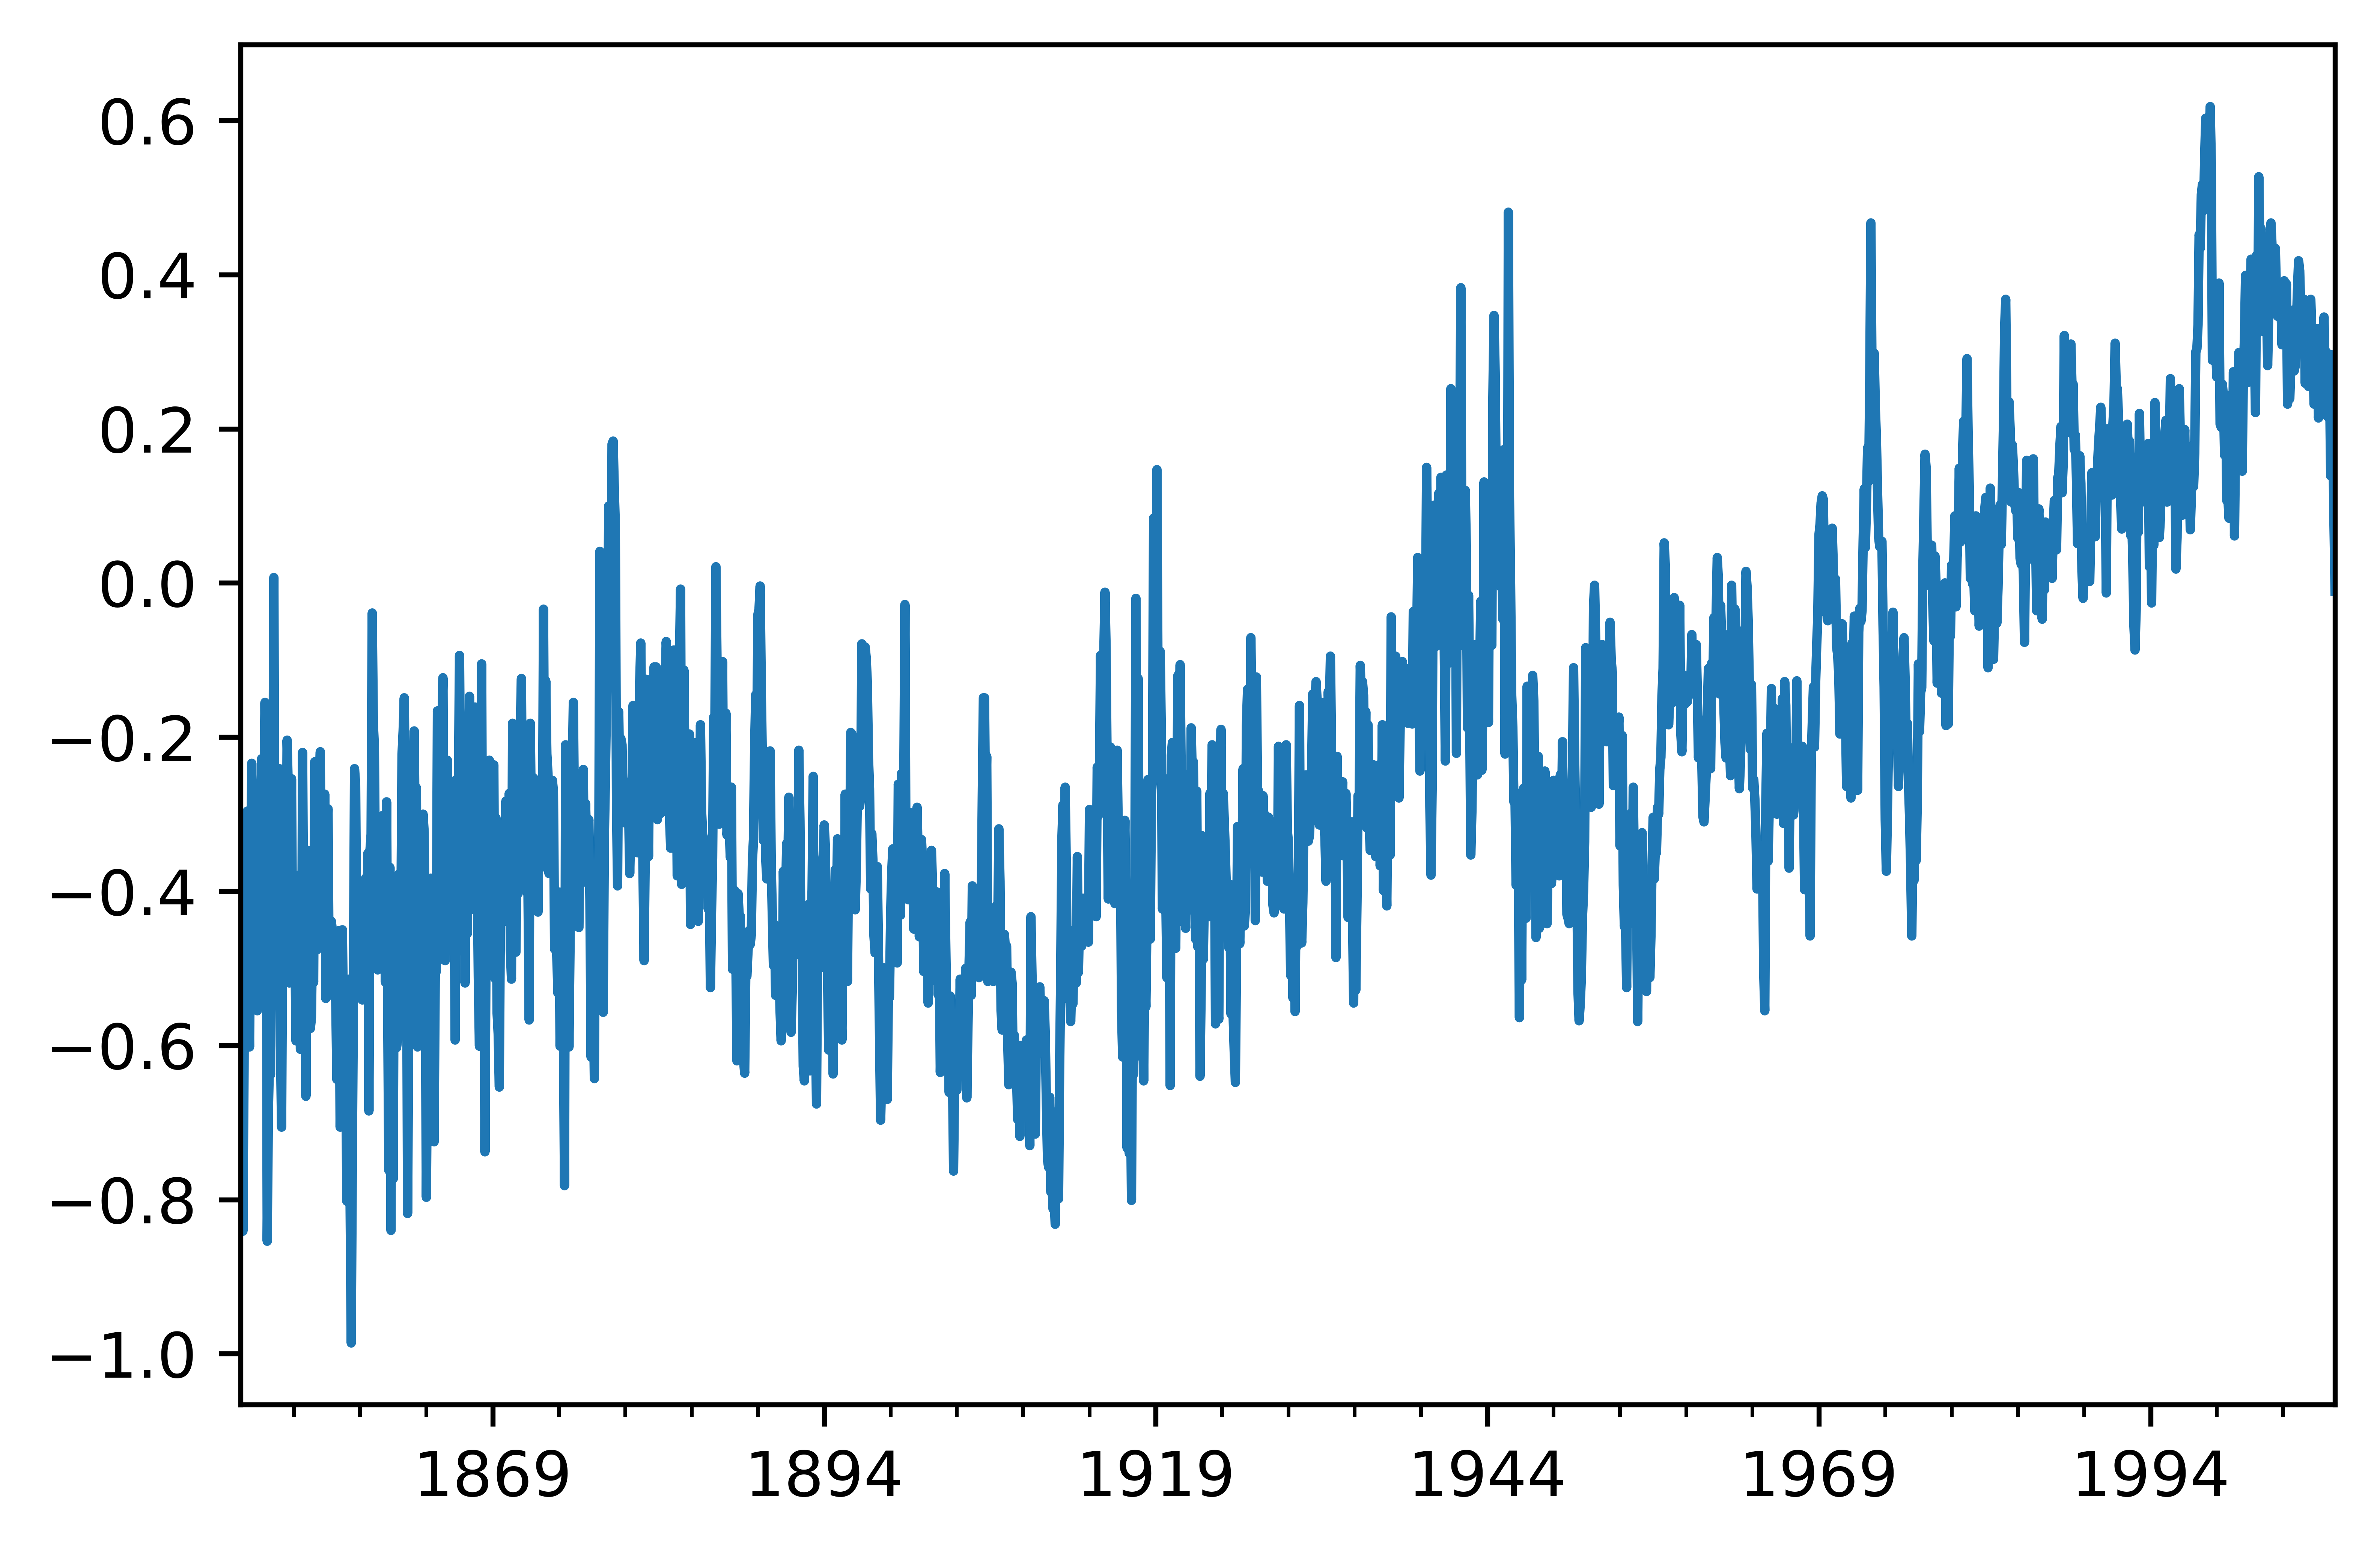

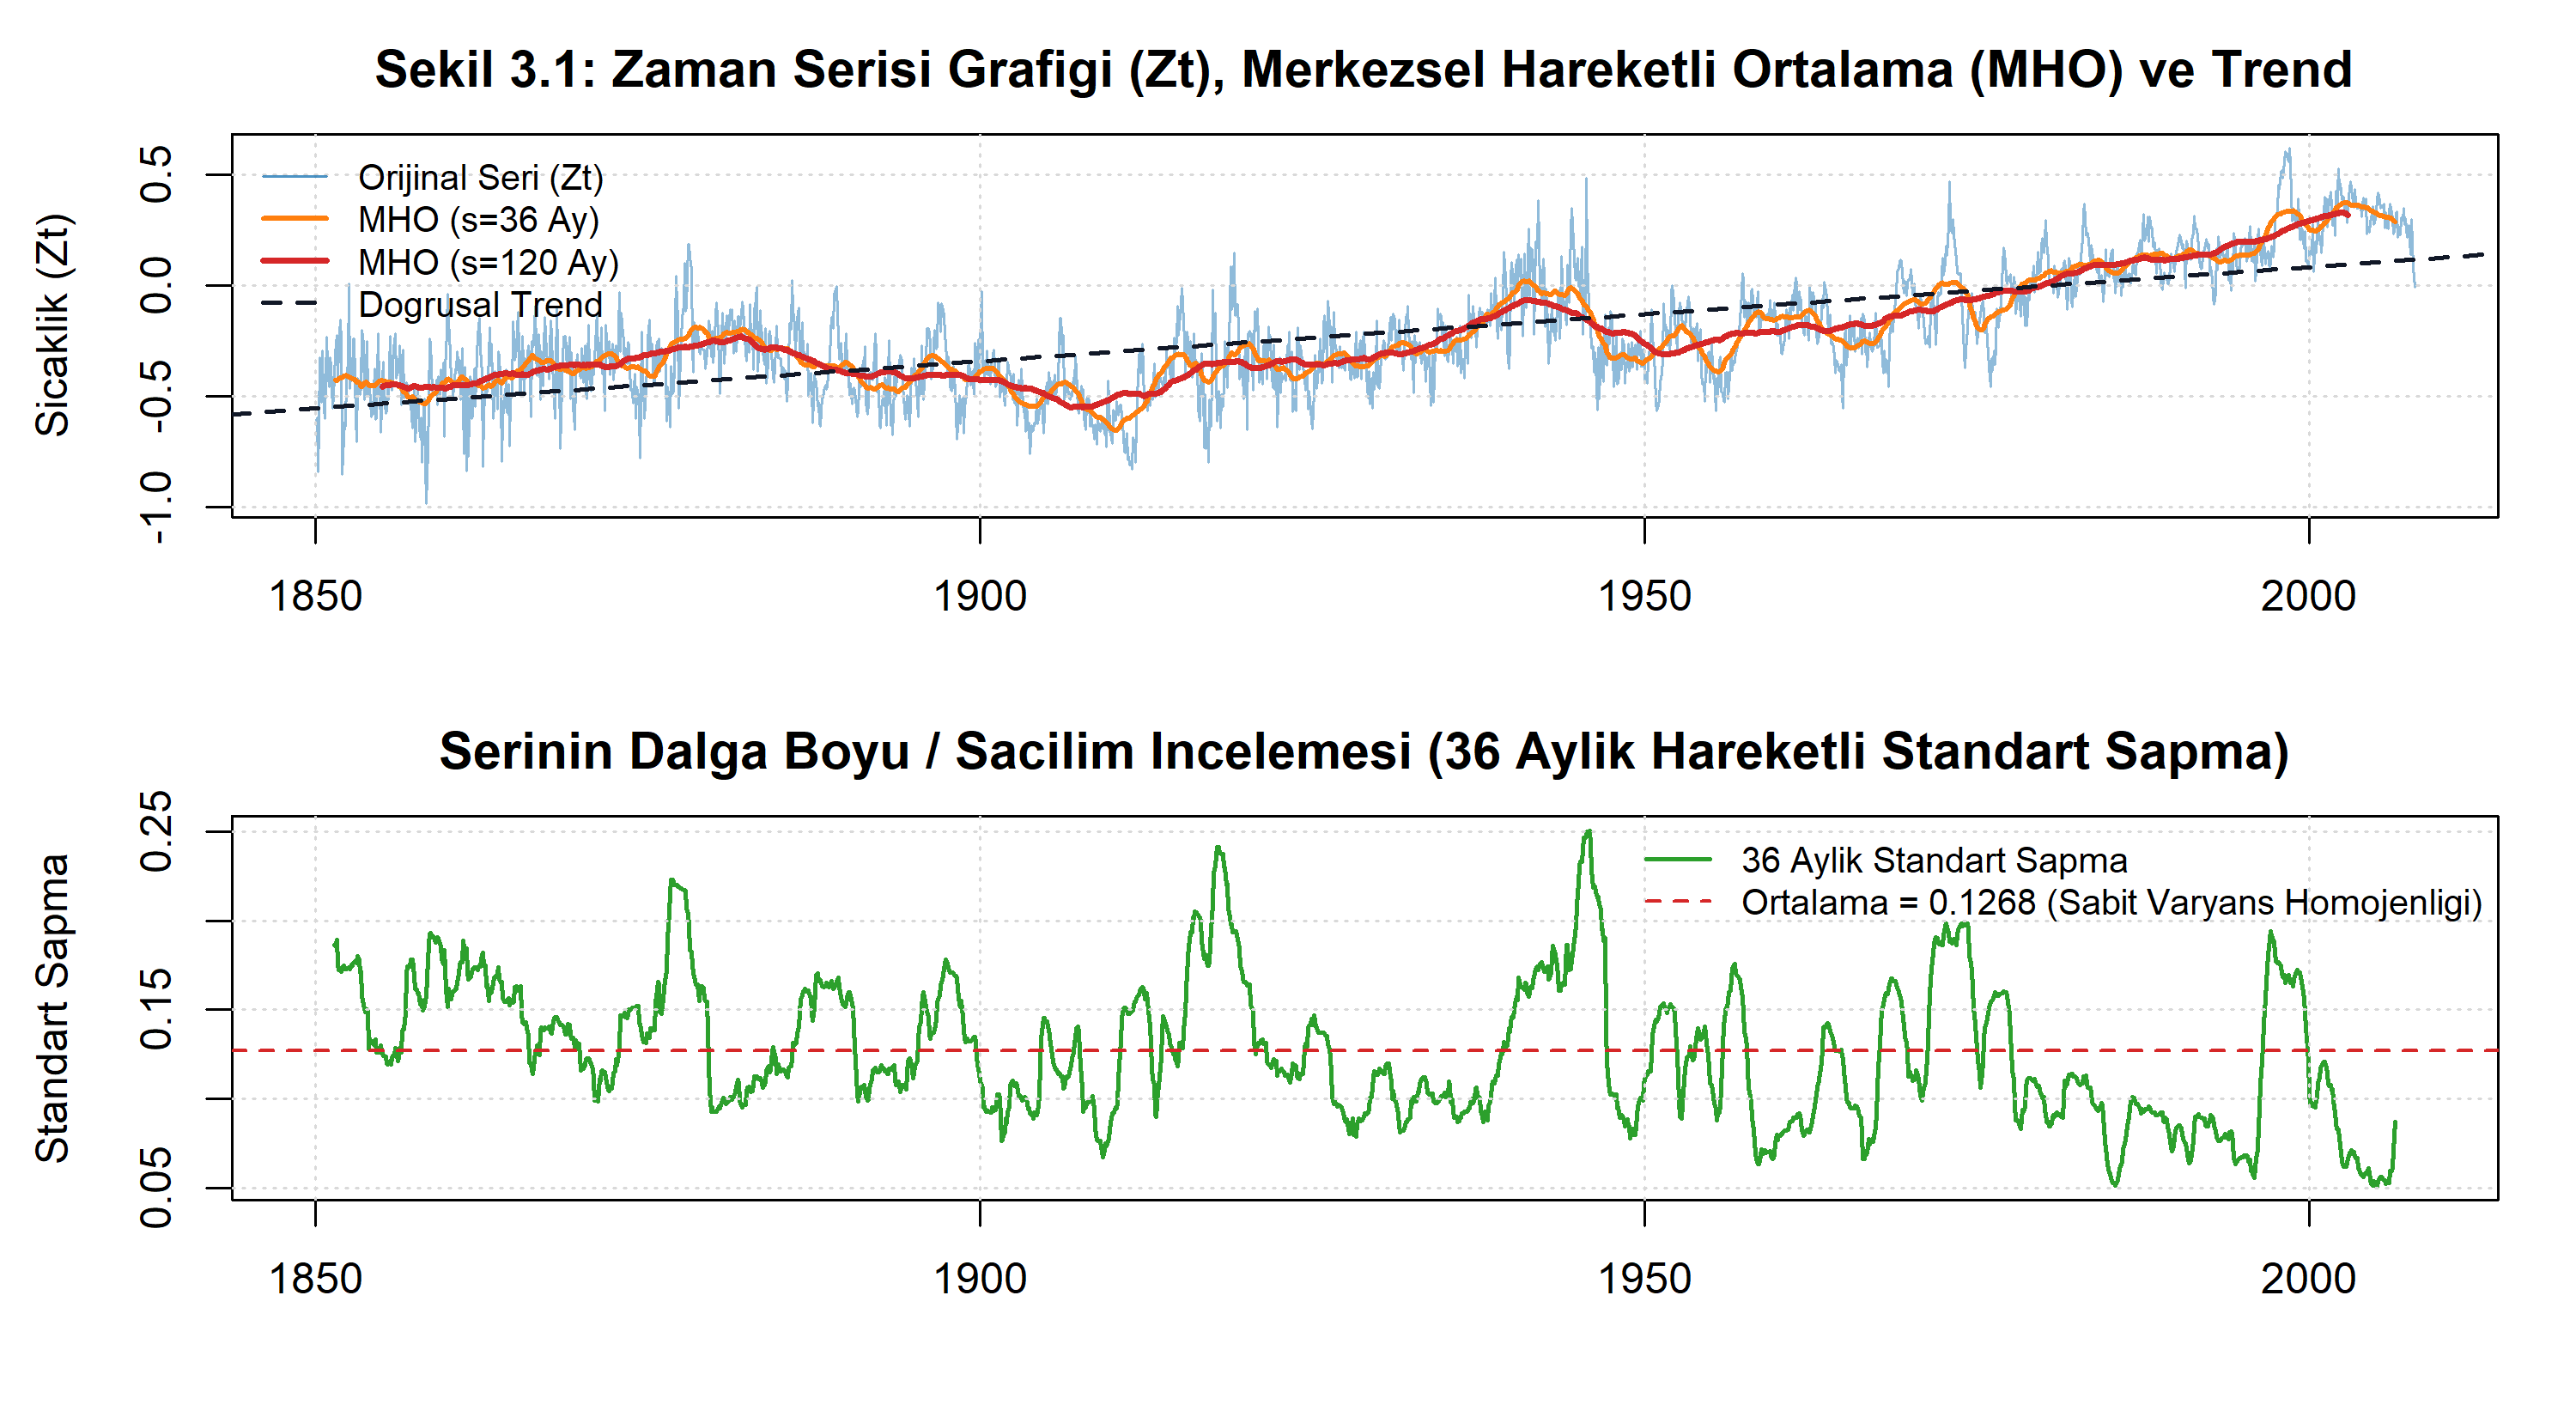

In [1]:
import numpy as np                        # Sayısal hesaplamalar için numpy
import pandas as pd                       # Veri ve zaman serisi için pandas
import matplotlib.pyplot as plt           # Grafik çizimi için matplotlib

# Veri setini boşluklara göre ayırarak okur (158 yıl x 12 ay = 1896 gözlem)
tem = pd.read_csv('Southtemperature.txt', header=None, sep=r'\s+')

# İlk iki satırı (1850 ve 1851 yılları) alt alta birleştirir
temts = pd.concat([tem.loc[0], tem.loc[1]], ignore_index=True)

# 1852-2007 yıllarını (2..157. satırlar) döngüyle uç uca ekler
for i in range(2, 158):
    temts = pd.concat([temts, tem.loc[i]], ignore_index=True)

# Ocak 1850'den itibaren 1896 aylık ('M') tarih dizisi oluşturur ve indeks yapar
dates = pd.date_range('1850', periods=len(temts), freq='M')
temts.index = dates                       # Tarih dizisini zaman indeksi atar

print('Veri Tipi           :', type(temts))          # Pandas Series veri tipi
print('Gözlem Sayısı (T)   :', len(temts))           # Toplam gözlem sayısı (1896)
print('Örneklem Ortalaması :', round(temts.mean(), 6)) # Ortalama = (1/T)*Sum(Z_t)
print('Standart Sapma (s)  :', round(temts.std(), 6))   # Örneklem standart sapması
print('Varyans (gamma_0)   :', round(temts.var(), 6))   # Örneklem varyansı

# Şekil 3.1: X ekseninde zaman (t), Y ekseninde Z_t olan zaman serisi grafiği
temts.plot(color='#1f77b4', linewidth=1.0) # Gözlemleri doğru parçalarıyla çizer
plt.savefig('pyTSA_TemperatureSH_fig3-1.png', dpi=1200,
            bbox_inches='tight', transparent=True, legend=None)
plt.show()                                # Grafiği ekranda gösterir

# Seriyi düzleştirmek için Merkezsel Hareketli Ortalama (MHO) hesabı
mho_36 = temts.rolling(window=36, center=True).mean()   # s=36 aylık MHO
mho_120 = temts.rolling(window=120, center=True).mean() # s=120 aylık MHO
std_36 = temts.rolling(window=36, center=True).std()    # 36 aylık dalga boyu

### 1.2 Yorum (Zaman Serisi Grafiği ve Bileşenleri — Şekil 3.1)
* **Gözlem Sıklığı ve Yapısı:** Seri, Ocak 1850 – Aralık 2007 döneminde her ay eşit aralıklarla kaydedilmiş $T = 1896$ gözlemden oluşan **aylık kesikli bir zaman serisidir** ($Z_t$).
* **1) Trend Bileşeni ($T_t$):** Şekil 3.1 ve Merkezsel Hareketli Ortalama (MHO, $s=36$ ve $s=120$; germe sayısı $s$ büyüdükçe seri daha düz hâle gelmektedir) incelendiğinde, serinin dönem boyunca **yukarı yönlü (artan) bir ana eğilime (trende)** sahip olduğu görülmektedir (1850–1910 arasında $-0.45^\circ\text{C}$ civarında iken 2000'li yıllarda $+0.40^\circ\text{C}$ / $+0.60^\circ\text{C}$ seviyesine çıkmıştır). **Trend varsa ortalama sabit değildir** ($E(Z_t) \ne \mu$); bu nedenle orijinal seri **durağan değildir**.
* **2) Mevsimsel ($M_t$) ve Döngüsel ($C_t$) Dalgalanma:** Seride her 12 ayda bir düzenli olarak tekrar eden sabit periyotlu bir mevsimsel dalgalanma baskın değildir; bunun yerine birkaç yıllık düzensiz aralıklarla yükseliş ve düşüş gösteren döngüsel (konjonktürel) ve düzensiz ($\varepsilon_t$) hareketler mevcuttur.
* **3) Varyans Homojenliği (Dalga Boyu):** Zaman serisinde varyansı belirleyen yer **dalga boyudur (saçılımdır)**. Alt paneldeki 36 aylık standart sapma grafiğinde görüldüğü üzere serinin dalga boyu zaman içinde büyüyüp patlamamakta, ortalama $0.1268$ etrafında yatay bir bantta kalmaktadır.

---
## 2. Gecikme İşlemcisi (Lag İşlemcisi)
### 2.1 Python Kodu ve Çıktısı

=== Gecikme İşlemcisi (B^k Z_t = Z_{t-k}) Tablosu (İlk 6 Gözlem) ===
              Z_t  B^1 Z_t = Z_{t-1}  B^2 Z_t = Z_{t-2}  B^12 Z_t = Z_{t-12}
1850-01-31 -0.625                NaN                NaN                  NaN
1850-02-28 -0.598             -0.625                NaN                  NaN
1850-03-31 -0.841             -0.598             -0.625                  NaN
1850-04-30 -0.632             -0.841             -0.598                  NaN
1850-05-31 -0.326             -0.632             -0.841                  NaN
1850-06-30 -0.528             -0.326             -0.632                  NaN

=== Orijinal Seri (Z_t) Gecikme Korelasyonları ===
Lag k= 1 -> Corr(Z_t, Z_{t-1})  = 0.8972
Lag k= 2 -> Corr(Z_t, Z_{t-2})  = 0.8667
Lag k= 3 -> Corr(Z_t, Z_{t-3})  = 0.8382
Lag k= 6 -> Corr(Z_t, Z_{t-6})  = 0.7938
Lag k=12 -> Corr(Z_t, Z_{t-12}) = 0.7424

=== 1. Fark Serisi (Delta Z_t) Gecikme Korelasyonları ===
Lag k= 1 -> Corr(Delta Z_t, Delta Z_{t-1})  = -0.3524
Lag k= 2 -> Corr(Delta

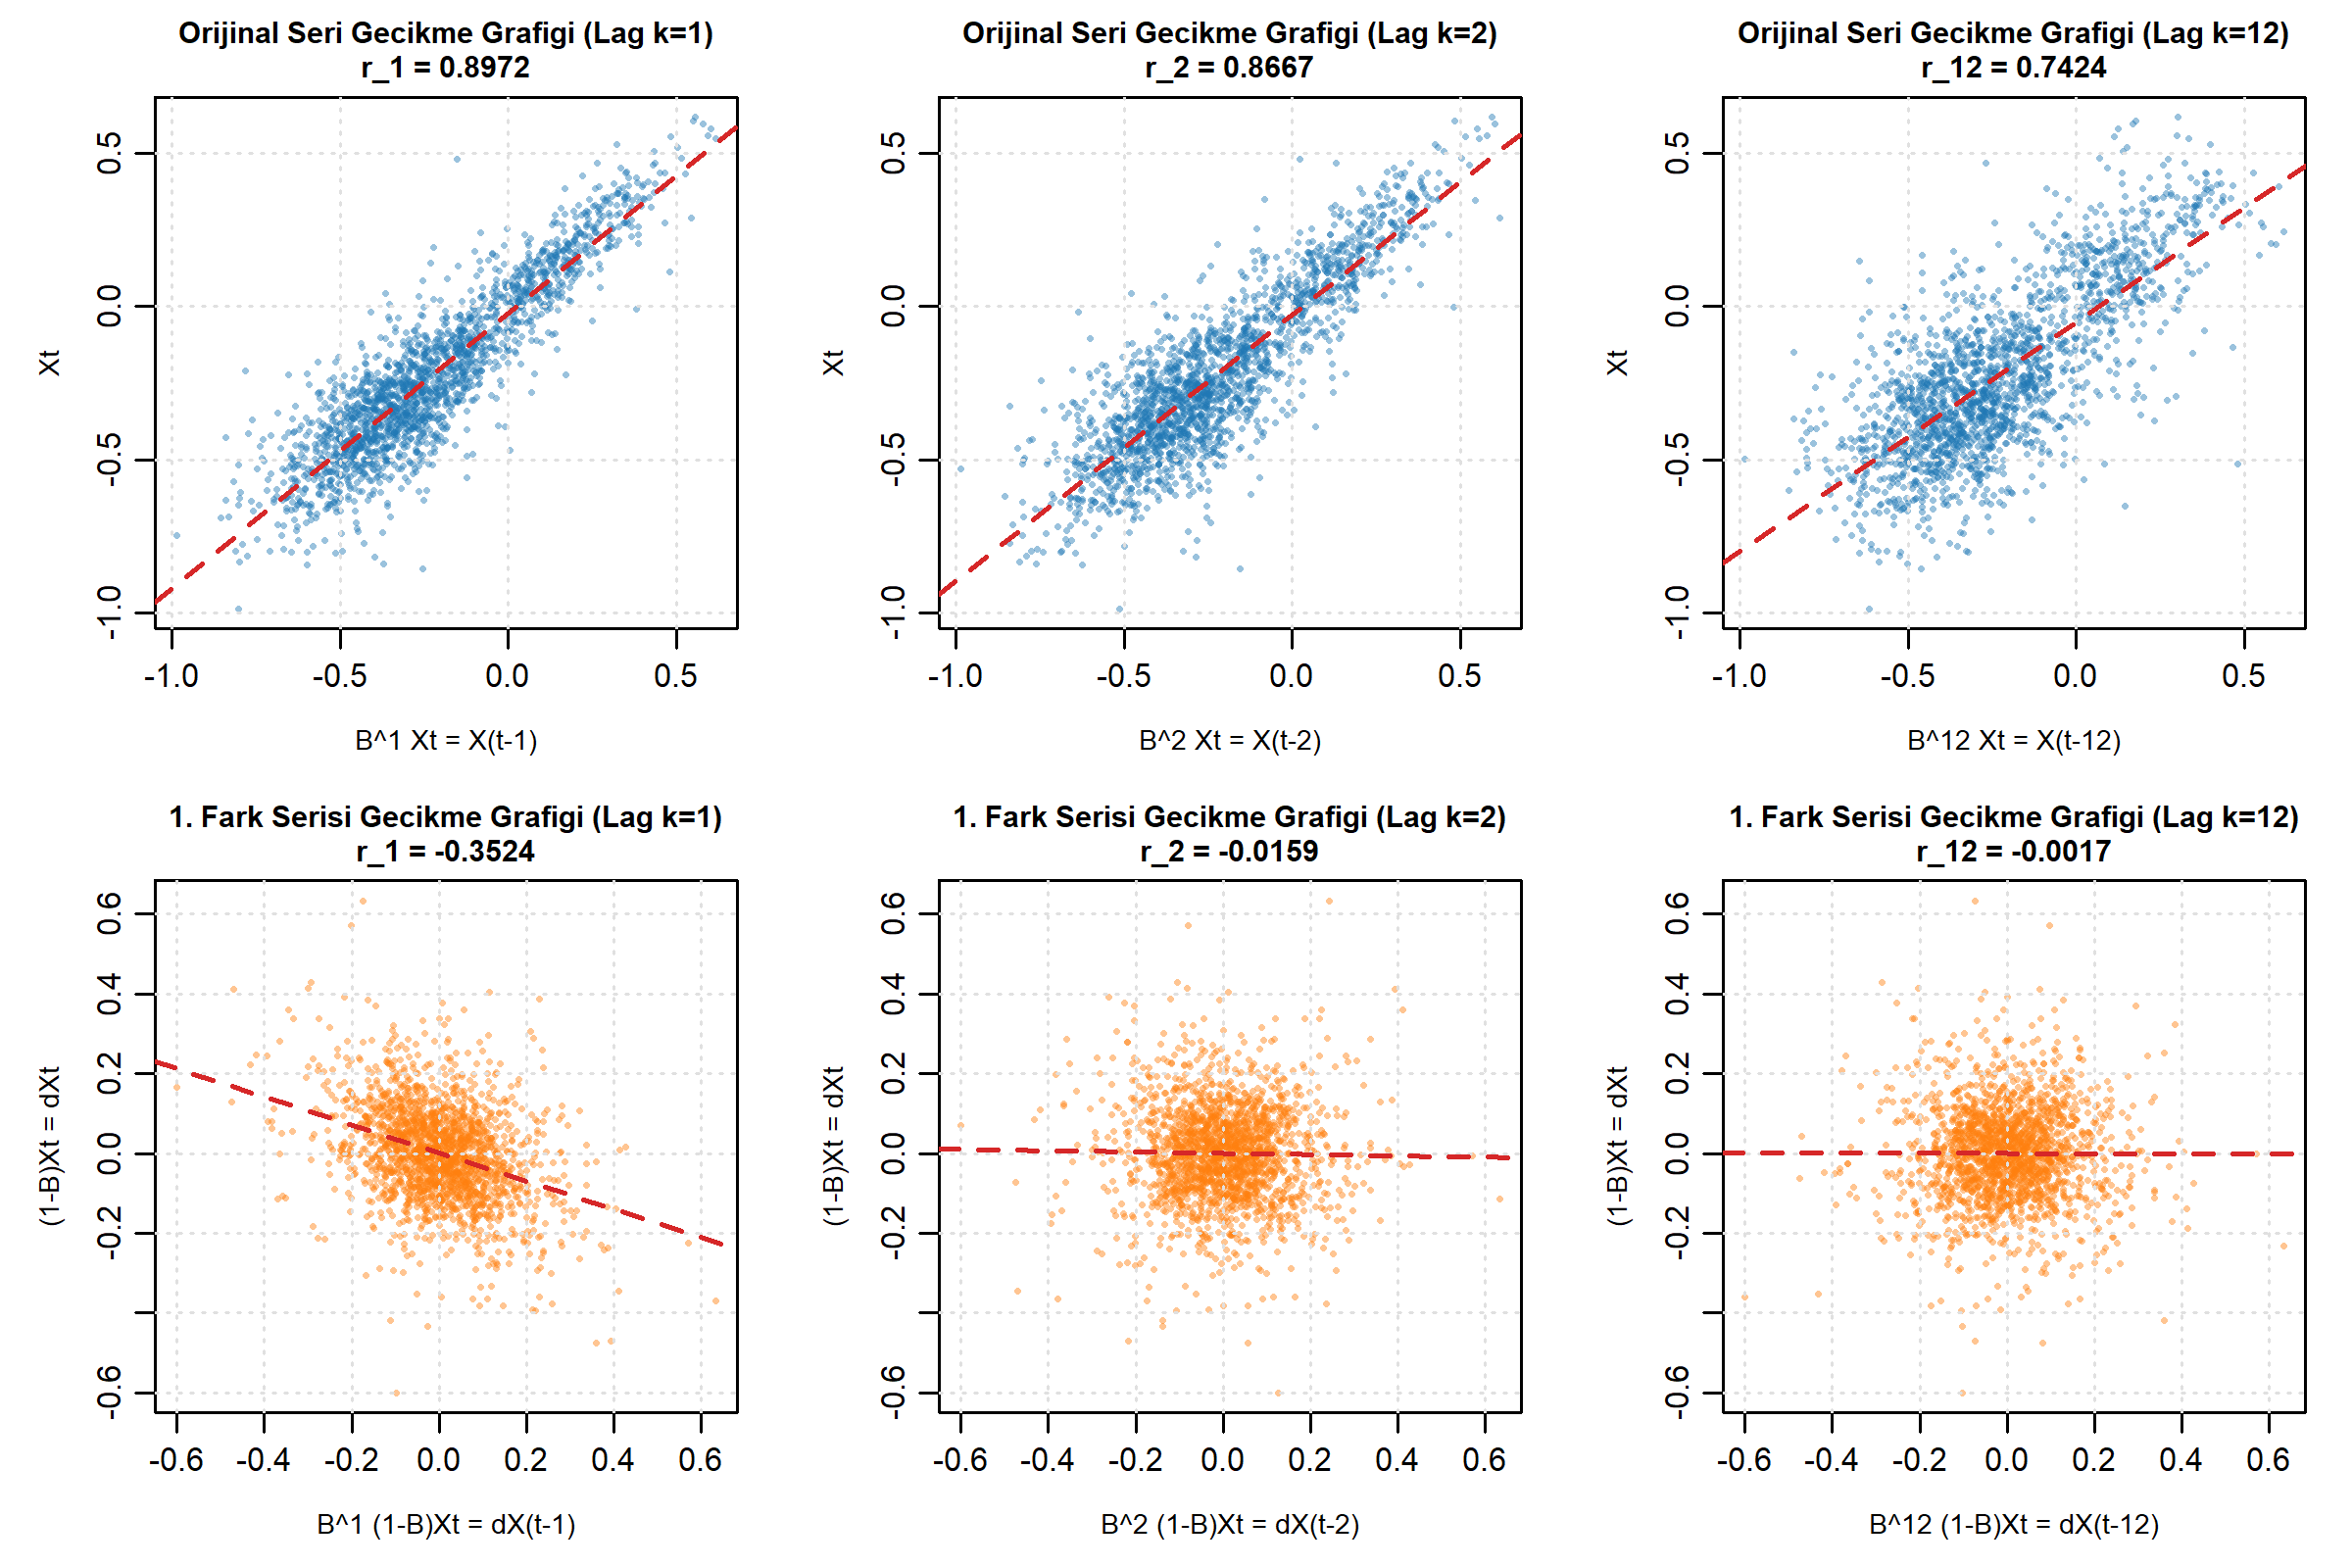

In [2]:
from pandas.plotting import lag_plot      # Gecikme saçılım grafiği fonksiyonu

# B gecikme işlemcisi olmak üzere k gecikmelisi: B^k Z_t = Z_{t-k} (.shift(k))
lag_df = pd.DataFrame({
    'Z_t': temts,                         # Orijinal seri (t dönemi gözlemi)
    'B^1 Z_t = Z_{t-1}': temts.shift(1),  # 1 dönem gecikmeli seri (Z_{t-1})
    'B^2 Z_t = Z_{t-2}': temts.shift(2),  # 2 dönem gecikmeli seri (Z_{t-2})
    'B^12 Z_t = Z_{t-12}': temts.shift(12)# 12 dönem gecikmeli seri (Z_{t-12})
})
print(lag_df.head(6))                     # İlk 6 ayı tablo olarak yazdırır

# Z_t ile gecikmeli serisi Z_{t-k} arasındaki Pearson korelasyon katsayısı (r_k)
for k in [1, 2, 3, 6, 12]:
    r_k = temts.corr(temts.shift(k))      # r_k = Cov(Z_t, Z_{t-k}) / (s_Z * s_Z)
    print(f'Lag k={k:2d} -> Corr(Z_t, Z_{{t-{k}}}) = {r_k:.4f}')

# Orijinal seri (Z_t) ve 1. fark serisi (Delta Z_t) gecikme saçılım grafikleri
dt = temts.diff(1).dropna()               # 1. fark serisi: Delta Z_t = Z_t - Z_{t-1}
fig, axes = plt.subplots(2, 3, figsize=(11, 7)) # 2x3 grafik paneli açar
for idx, k in enumerate([1, 2, 12]):
    lag_plot(temts, lag=k, ax=axes[0, idx]) # Üst satır: Orijinal seri (Z_t)
    lag_plot(dt, lag=k, ax=axes[1, idx])    # Alt satır: 1. fark serisi (Delta Z_t)
plt.tight_layout()                        # Grafik panellerini hizalar
plt.show()                                # Grafiği ekranda gösterir

### 2.2 Yorum (Gecikme İşlemcisi ve Gecikme Grafikleri)
* **Dönem Kaydırma Tablosu ($B^k Z_t = Z_{t-k}$):** Zaman serisi verilerinin $k$ dönem kaydırılmasıyla gecikmeli seriler elde edilmiştir. Örneğin $Z_1 = -0.625$ (Ocak 1850) değeri, $k=1$ dönem kaydırıldığında $Z_{t-1}$ sütununda 2. satıra (Şubat 1850), $k=2$ dönem kaydırıldığında $Z_{t-2}$ sütununda 3. satıra (Mart 1850) geçmiştir. İlk $k$ satırda önceki dönem verisi olmadığı için `NaN` (boş) oluşmaktadır.
* **Orijinal Seri Gecikme Grafiği (Üst Panel):** $(Z_1, Z_{1+k}), \dots, (Z_{T-k}, Z_T)$ ikilileri arasındaki ilişki incelendiğinde, $k=1$ için $r_1 = 0.8972$, $k=2$ için $r_2 = 0.8667$ ve $k=12$ için $r_{12} = 0.7424$ gibi çok yüksek pozitif korelasyonlar vardır. Noktaların $45^\circ$'lik doğru etrafında toplanması, birbirine yakın gözlemler arasında güçlü bir pozitif bağımlılık (trend etkisi) olduğunu göstermektedir.
* **1. Fark Serisi Gecikme Grafiği (Alt Panel):** Serinin 1. farkı ($\Delta Z_t$) alındıktan sonra trend yok olduğu için sadece $k=1$ gecikmesinde negatif bir ilişki ($r_1 = -0.3524$) kalmış, $k=2$ ($r_2 = -0.0159$) ve $k=12$ ($r_{12} = -0.0017$) gecikmelerinde noktalar sıfır etrafında rastgele küresel bir bulut oluşturmuştur.

---
## 3. Fark İşlemcisi (Difference İşlemcisi)
### 3.1 Python Kodu ve Çıktısı

=== Fark İşlemcisi Sonuçları ve Varyans Karşılaştırma Tablosu ===
                  Seri  Gözlem (T)   Ortalama  Std. Sapma   Varyans
   Orijinal Seri (Z_t)        1896  -0.221604    0.270654  0.073254
1. Dereceden Fark (dt)        1895   0.000324    0.122714  0.015059
2. Dereceden Fark(dt2)        1894  -0.000062    0.201855  0.040746
  Mevsimsel Fark(dt12)        1884   0.004561    0.193584  0.037475

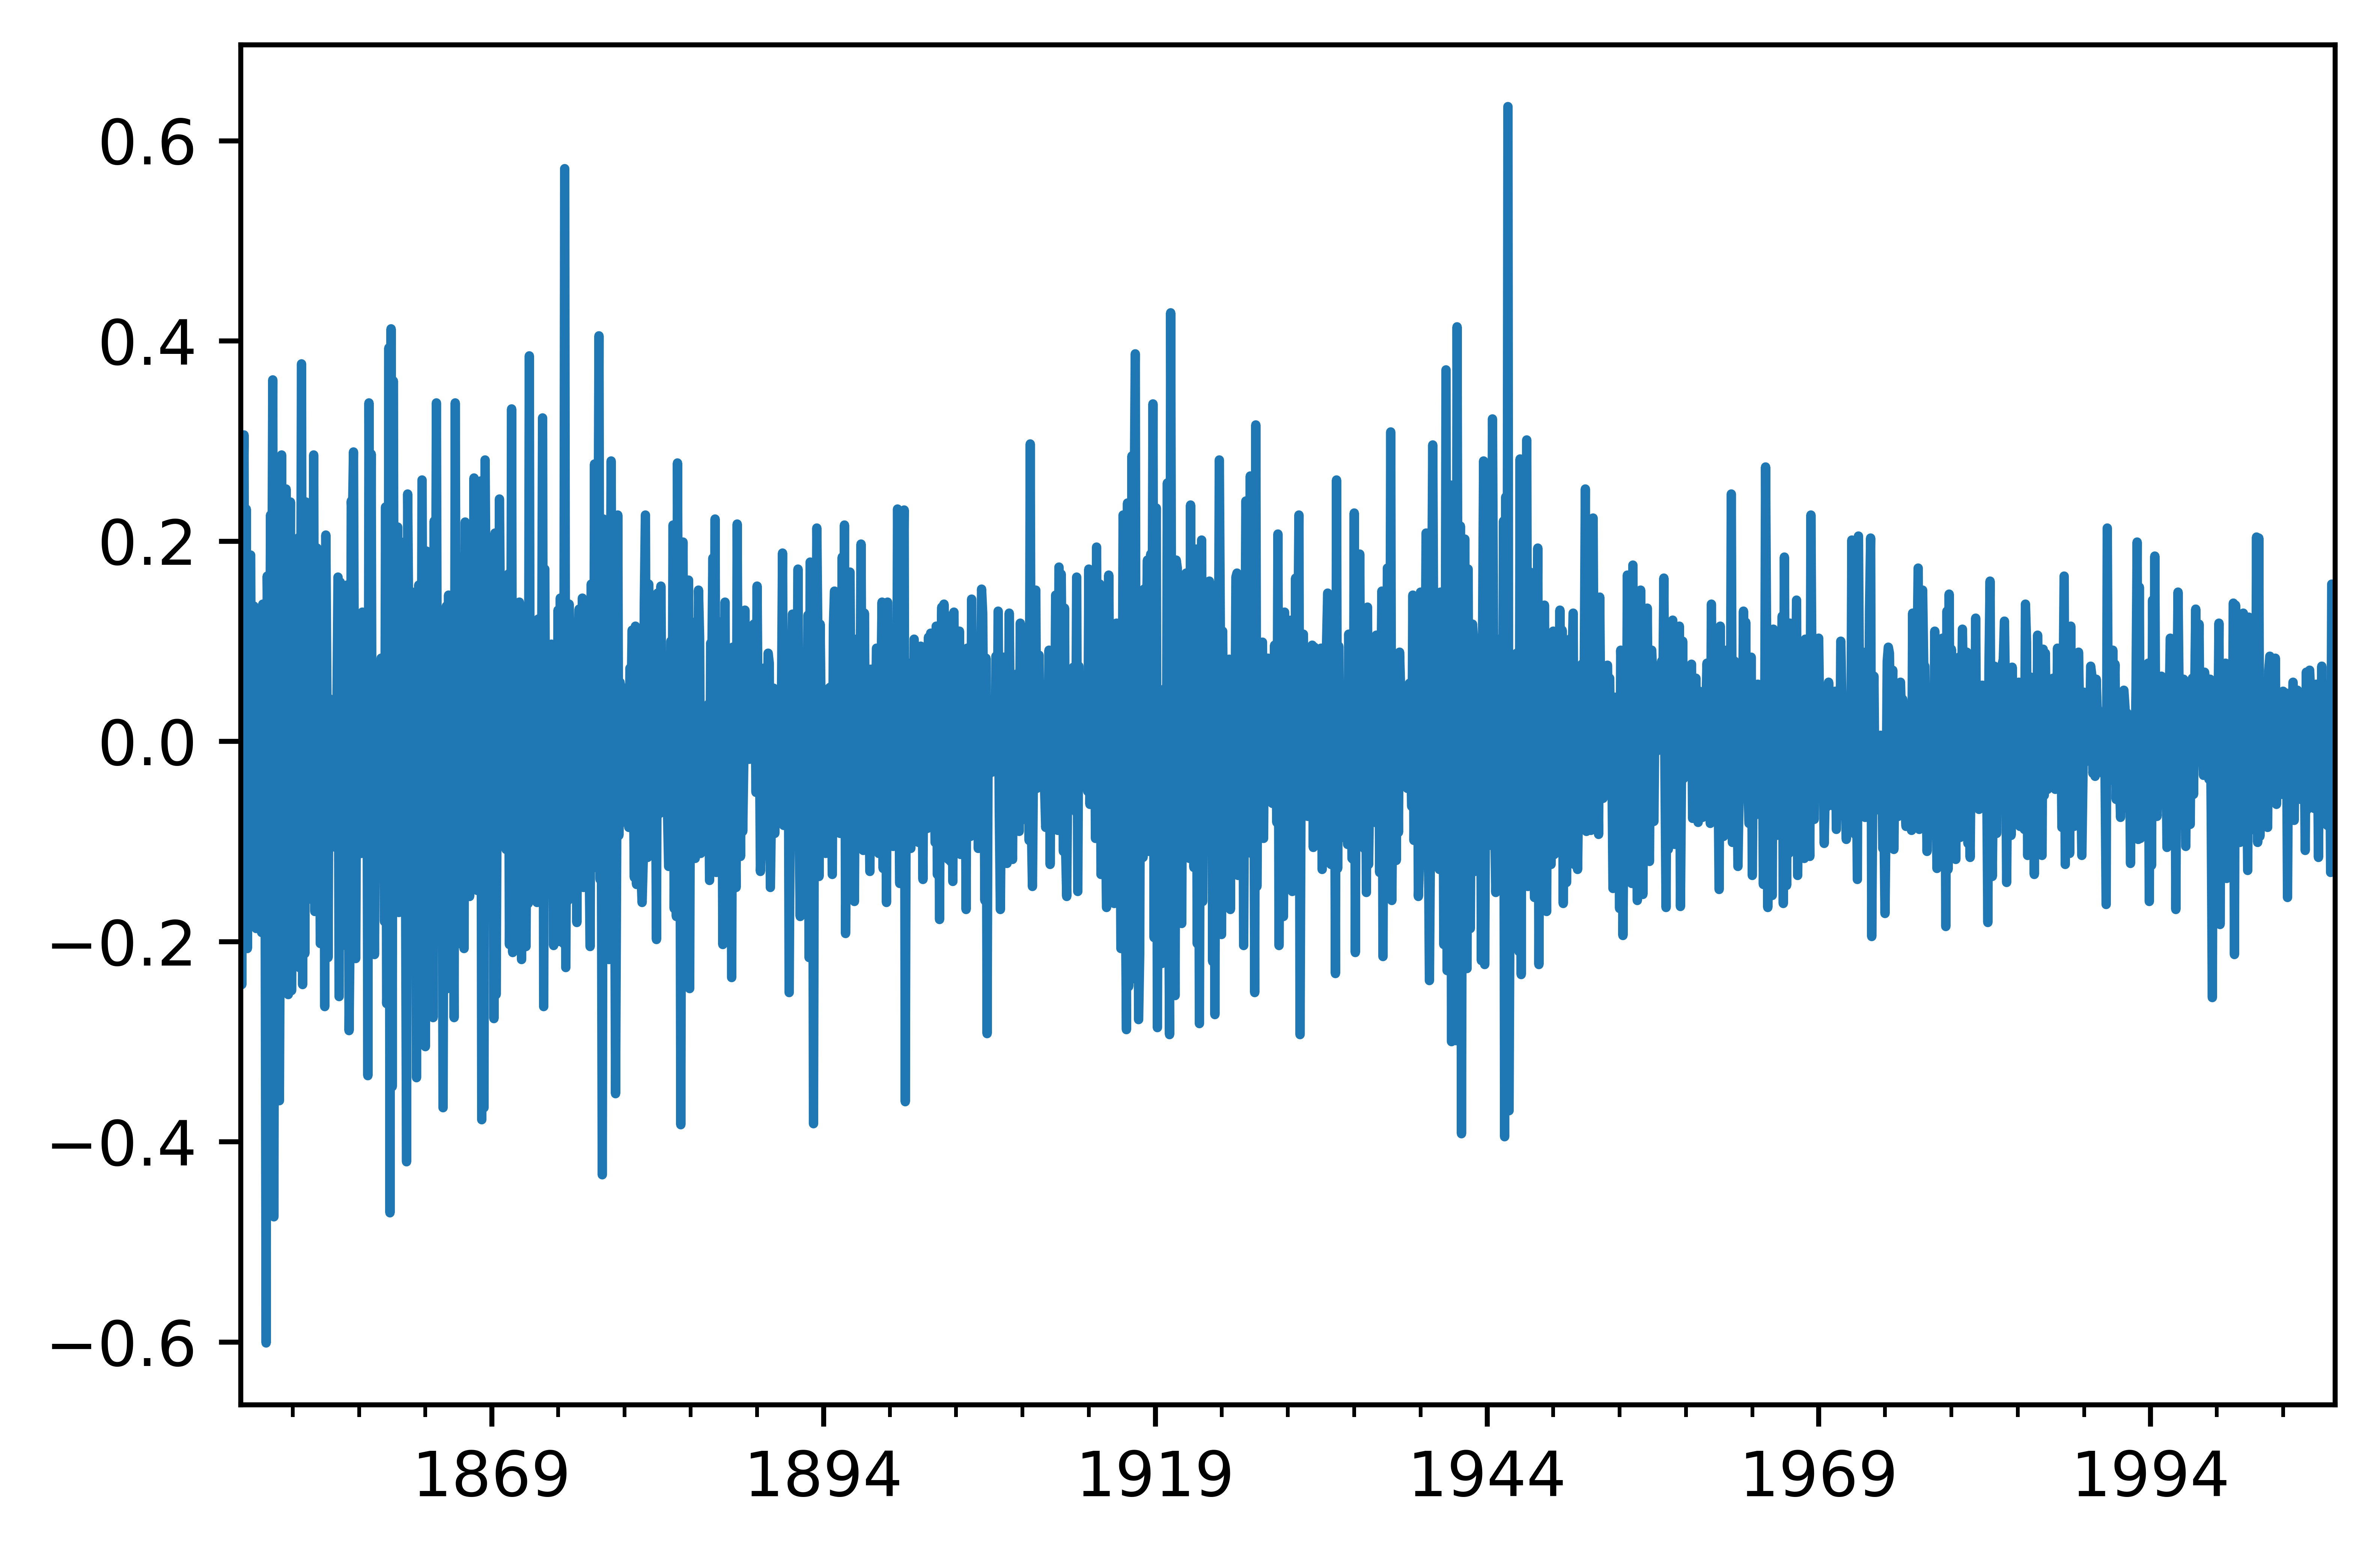

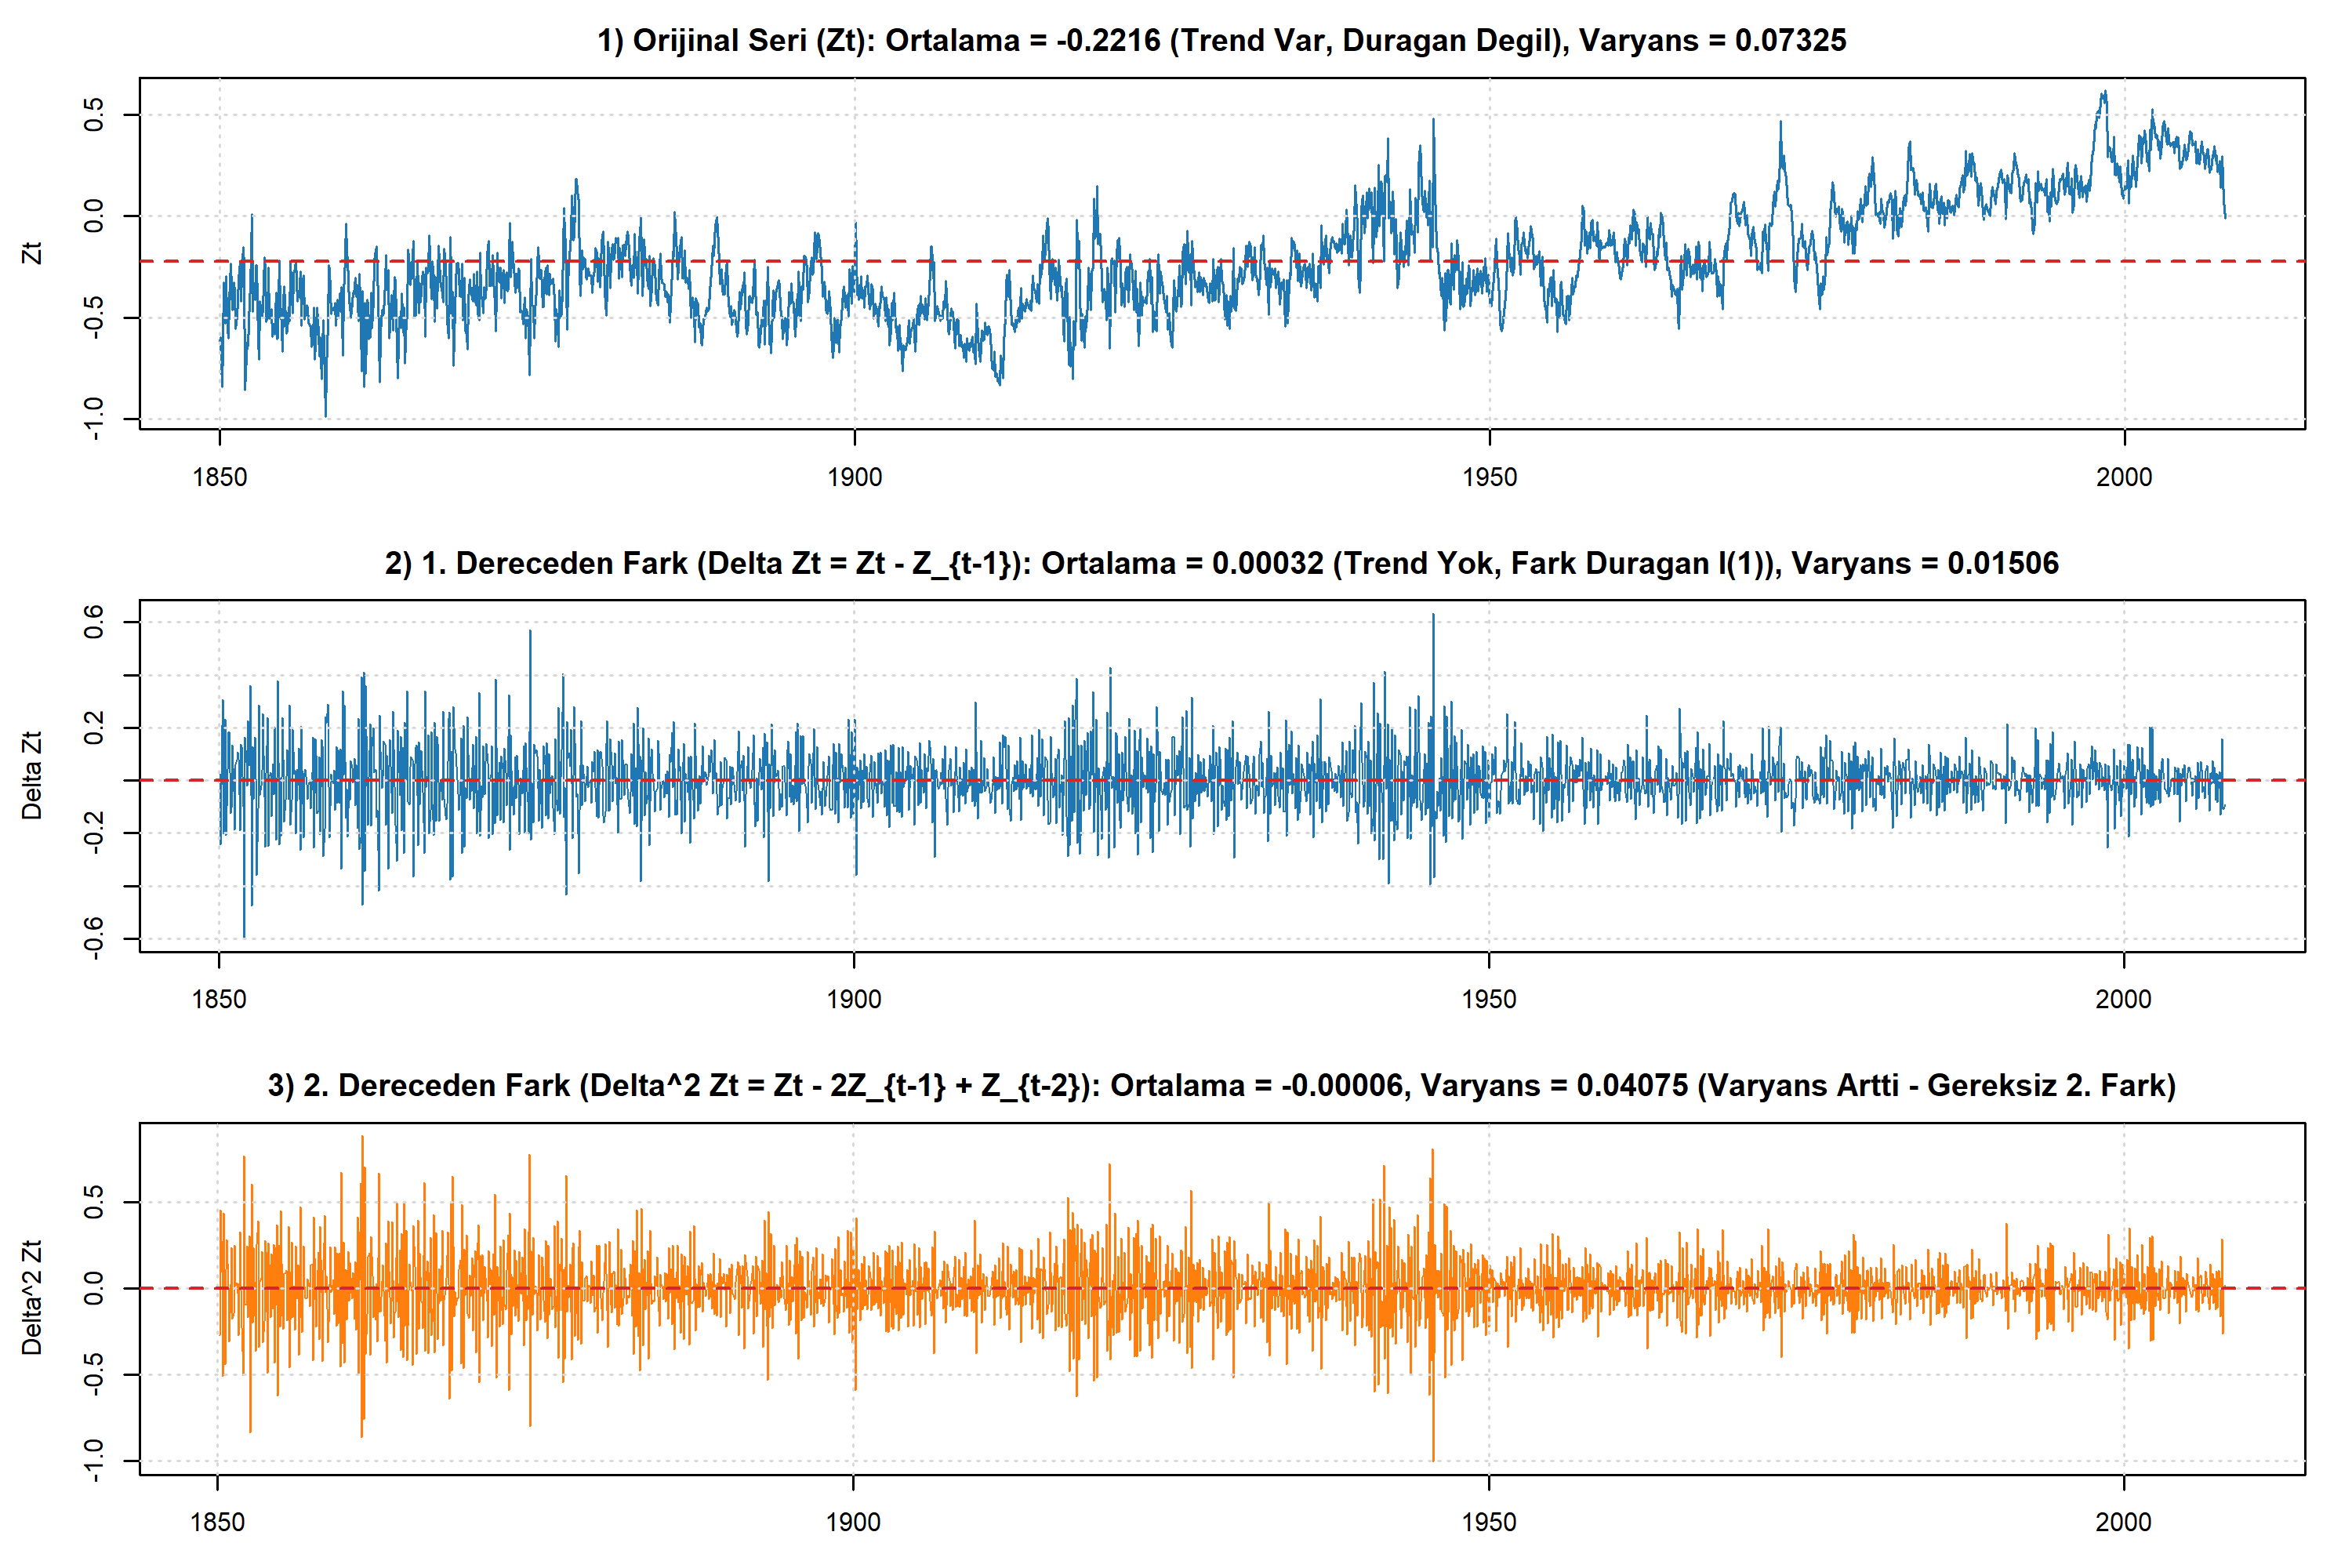

In [3]:
# 1. dereceden fark: Delta Z_t = Z_t - Z_{t-1} = (1 - B)Z_t
dt = temts.diff(1)                        # Son değerden 1 önceki değeri çıkarır
dt = dt.dropna()                          # İlk gözlemdeki NaN değerini siler

# 2. dereceden fark: Delta^2 Z_t = Delta(Delta Z_t) = Z_t - 2Z_{t-1} + Z_{t-2}
dt2 = temts.diff(1).diff(1).dropna()      # (1 - B)^2 Z_t (2. dereceden fark)

# Mevsimsel fark (periyot s=12): Delta_12 Z_t = Z_t - Z_{t-12} = (1 - B^12)Z_t
dt12 = temts.diff(12).dropna()            # 12 dönem önceki değerden fark alır

# Birinci farkı alınmış serinin (Delta Z_t) zaman serisi grafiğini çizer
dt.plot(color='#1f77b4', linewidth=0.9)   # 1. fark serisini zamana göre çizer
plt.savefig('pyTSA_TemperatureSH_fig3-2.png', dpi=1200,
            bbox_inches='tight', transparent=True, legend=None)
plt.show()                                # Grafiği ekranda gösterir

### 3.2 Yorum (Fark İşlemcisi)
* **Trendin Yok Edilmesi ("Trend Yoksa Ortalama Sabittir"):** Fark işlemcisi sayesinde serideki trendi yok etmek mümkün olmaktadır. Şekil 3.1'deki orijinal seriye 1. dereceden fark işlemi ($\Delta Z_t = Z_t - Z_{t-1}$) uygulandığında, yukarı yönlü artan trend tamamen ortadan kalkmıştır. Elde edilen fark serisi **$0$ sabit ortalaması ($0.000324$)** etrafında yatay olarak dalgalanmaktadır.
* **Sabit Sıçramalı Varyans ve Derece Seçimi ($d=1$):** 1. fark serisinin grafiğinde dalga boyu zaman boyunca homojendir ve örneklem varyansı $0.073254$'ten **$0.015059$'a** düşmüştür. Seriye 2. dereceden fark ($\Delta^2 Z_t = Z_t - 2Z_{t-1} + Z_{t-2}$) uygulandığında ise varyans **$0.040746$'ya** yükselmektedir. Dolayısıyla serideki trendi yok etmek ve durağanlığı sağlamak için **1. dereceden fark almak ($d=1$)** tam ve yeterlidir.

---
## 4. ACF ve PACF Grafikleri
### 4.1 Python Kodu ve Çıktısı

=== 1. Fark Serisi (Delta Z_t) İçin ACF / PACF Önemlilik Testleri ===
  k      r_k  Bartlett_Srk  t_Bartlett  t_Moran     r_kk  t_PACF
  1  -0.3523        0.0230      -15.34   -15.35  -0.3523  -15.34
  2  -0.0159        0.0257       -0.62    -0.69  -0.1599   -6.96
  3  -0.0632        0.0257       -2.46    -2.75  -0.1476   -6.43
  4  -0.0004        0.0258       -0.01    -0.02  -0.0997   -4.34
  5   0.0020        0.0258        0.08     0.09  -0.0624   -2.72
  6   0.0026        0.0258        0.10     0.12  -0.0408   -1.77
  7  -0.0164        0.0258       -0.64    -0.71  -0.0475   -2.07
  8  -0.0198        0.0258       -0.77    -0.87  -0.0608   -2.65
  9   0.0227        0.0258        0.88     0.99  -0.0214   -0.93
 10  -0.0631        0.0258       -2.45    -2.76  -0.0916   -3.99
 11   0.0551        0.0259        2.13     2.41  -0.0175   -0.76
 12  -0.0017        0.0259       -0.06    -0.07  -0.0062   -0.27

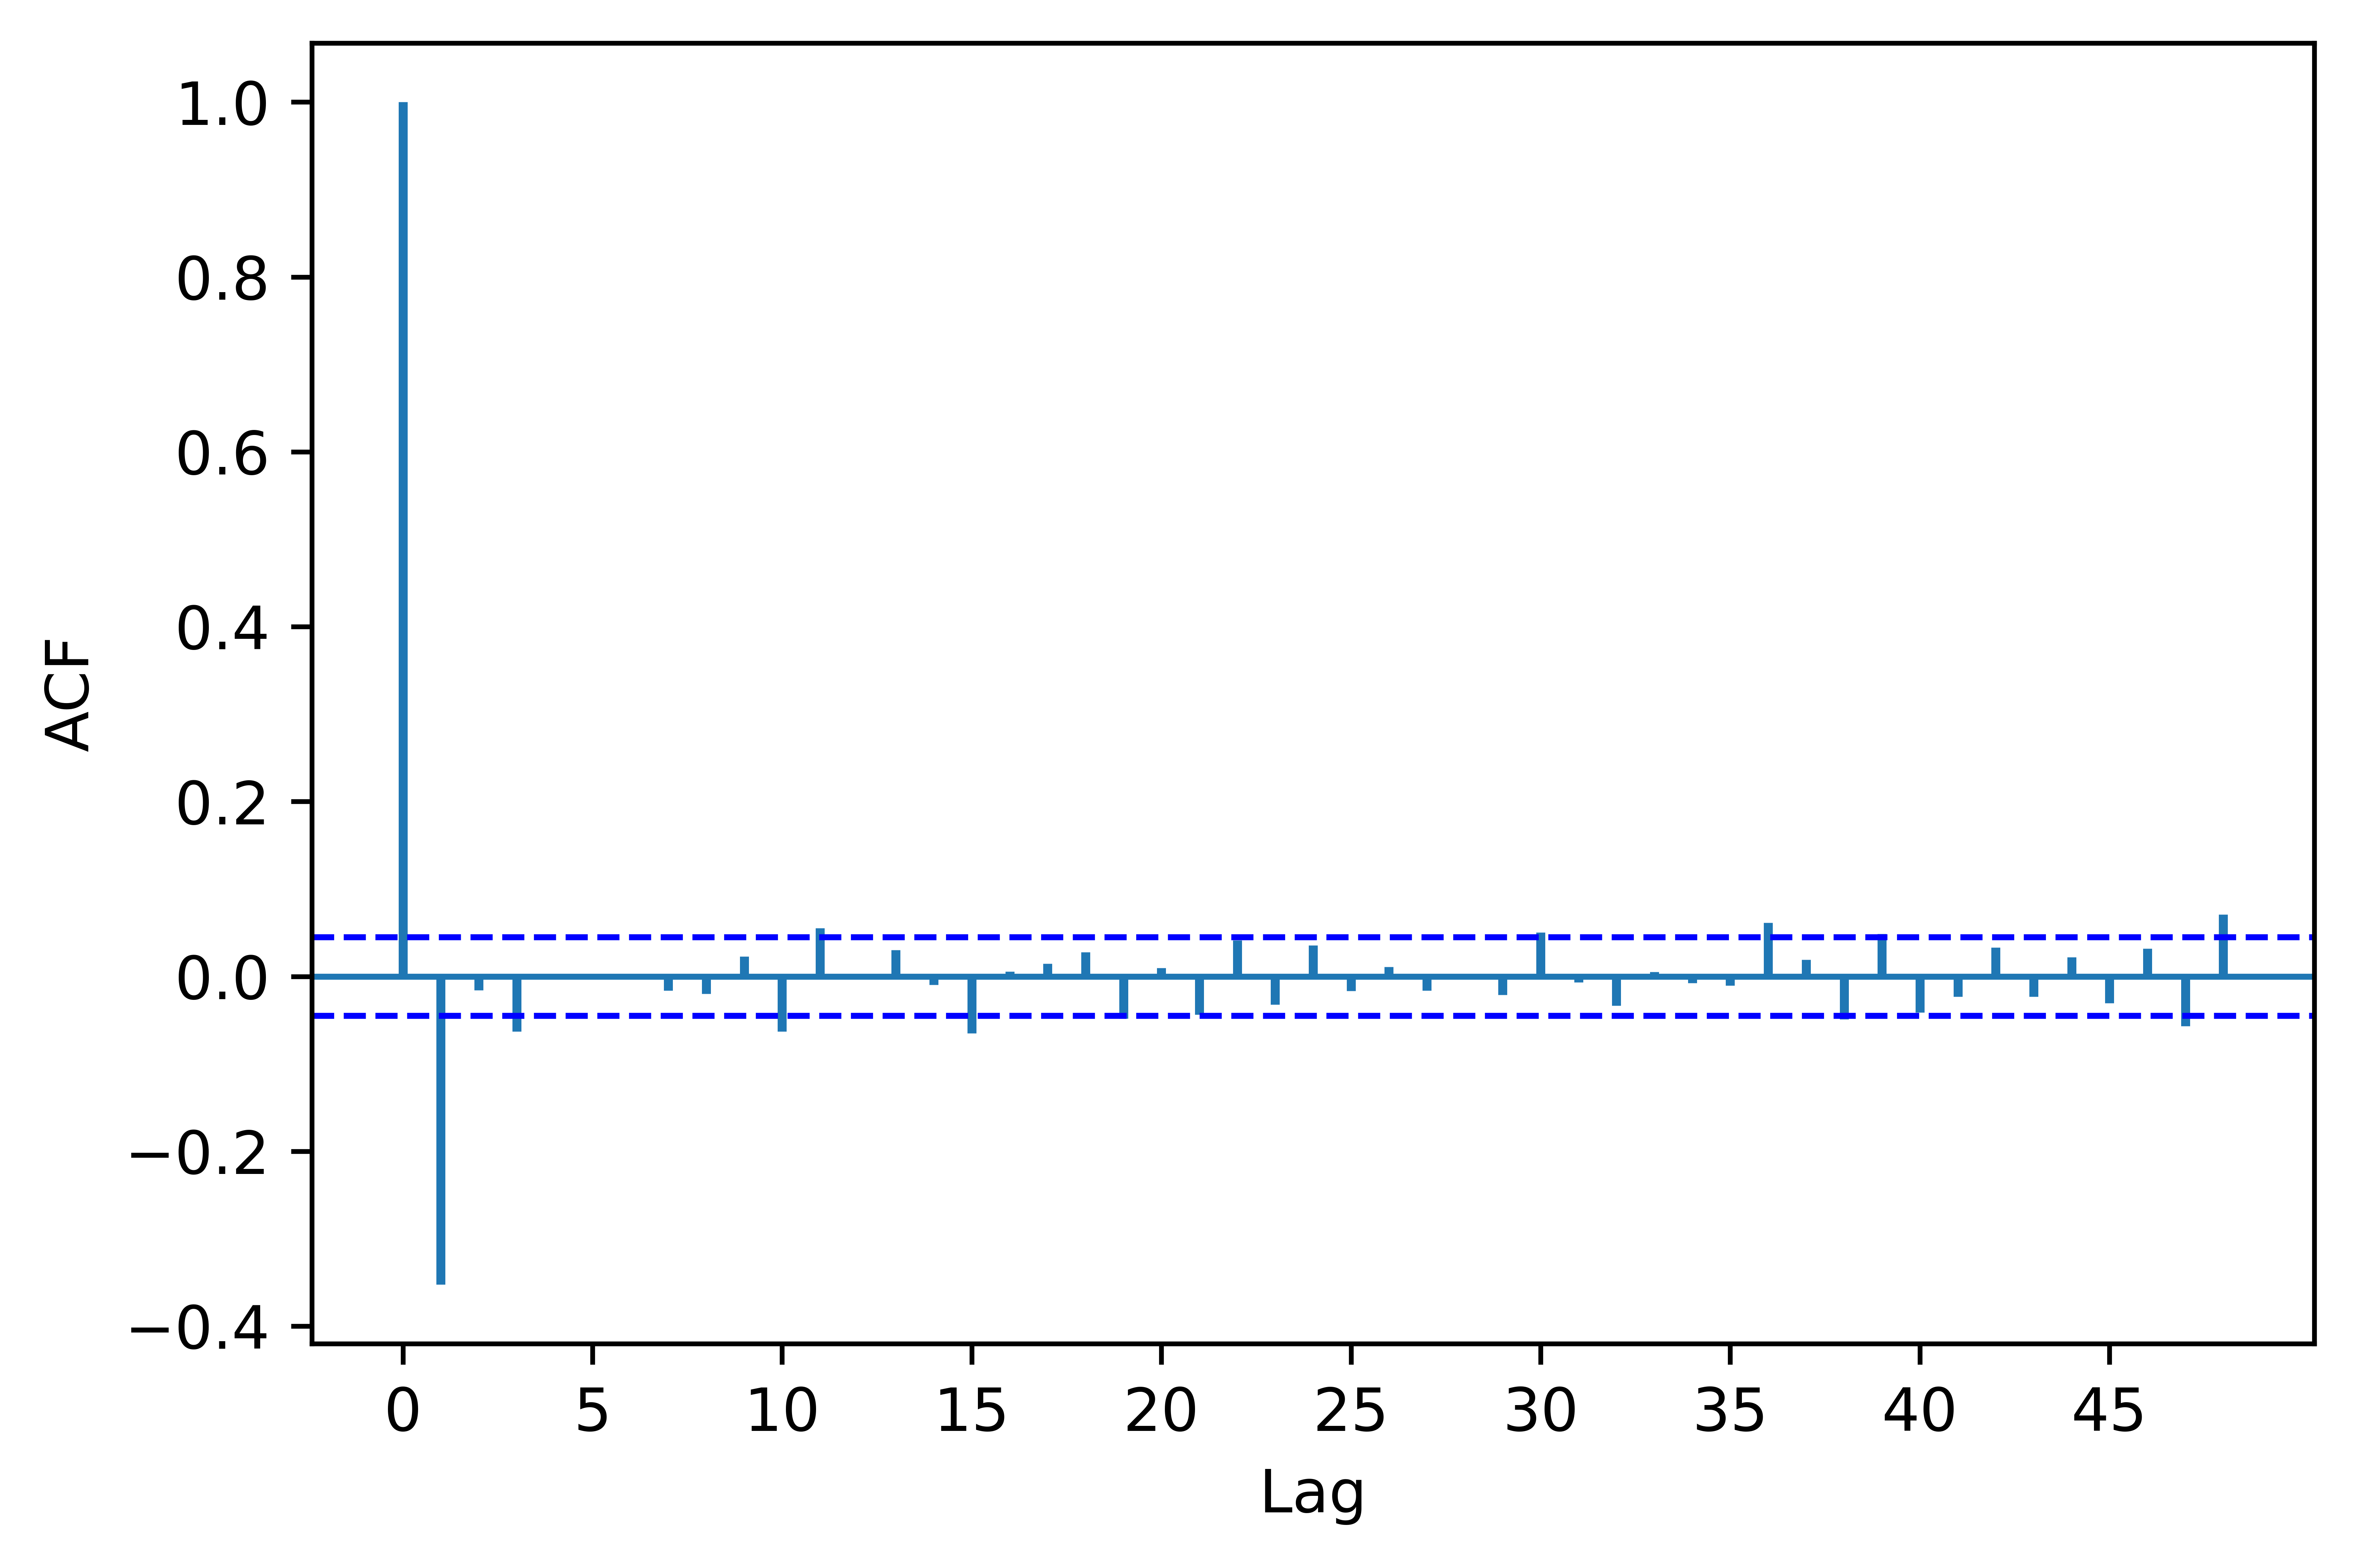

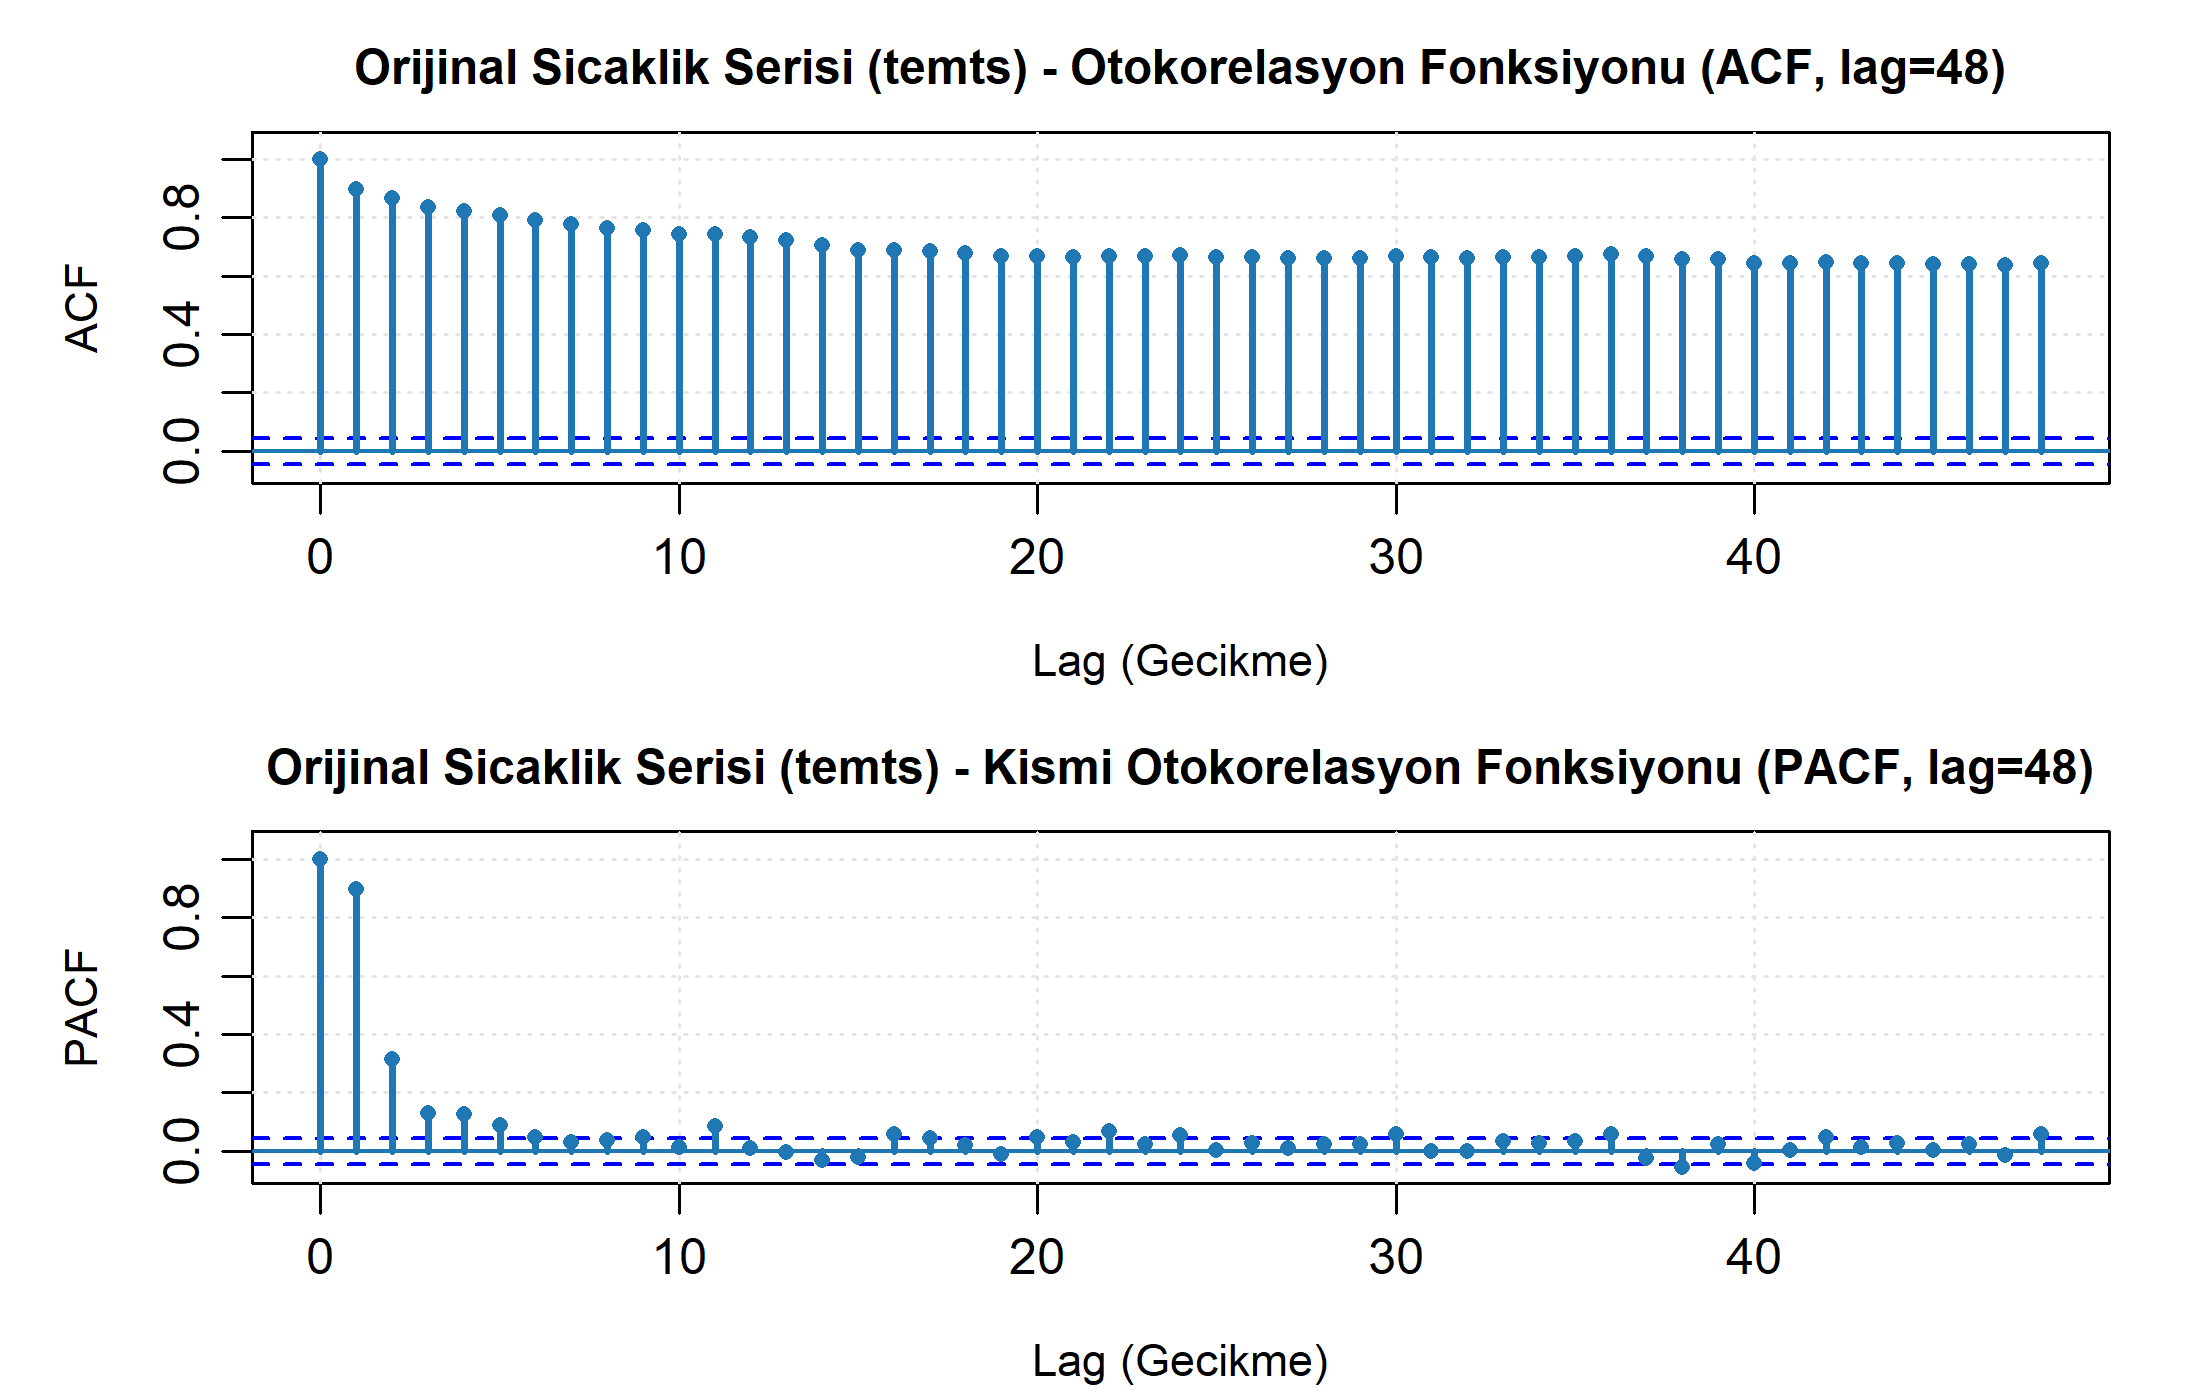

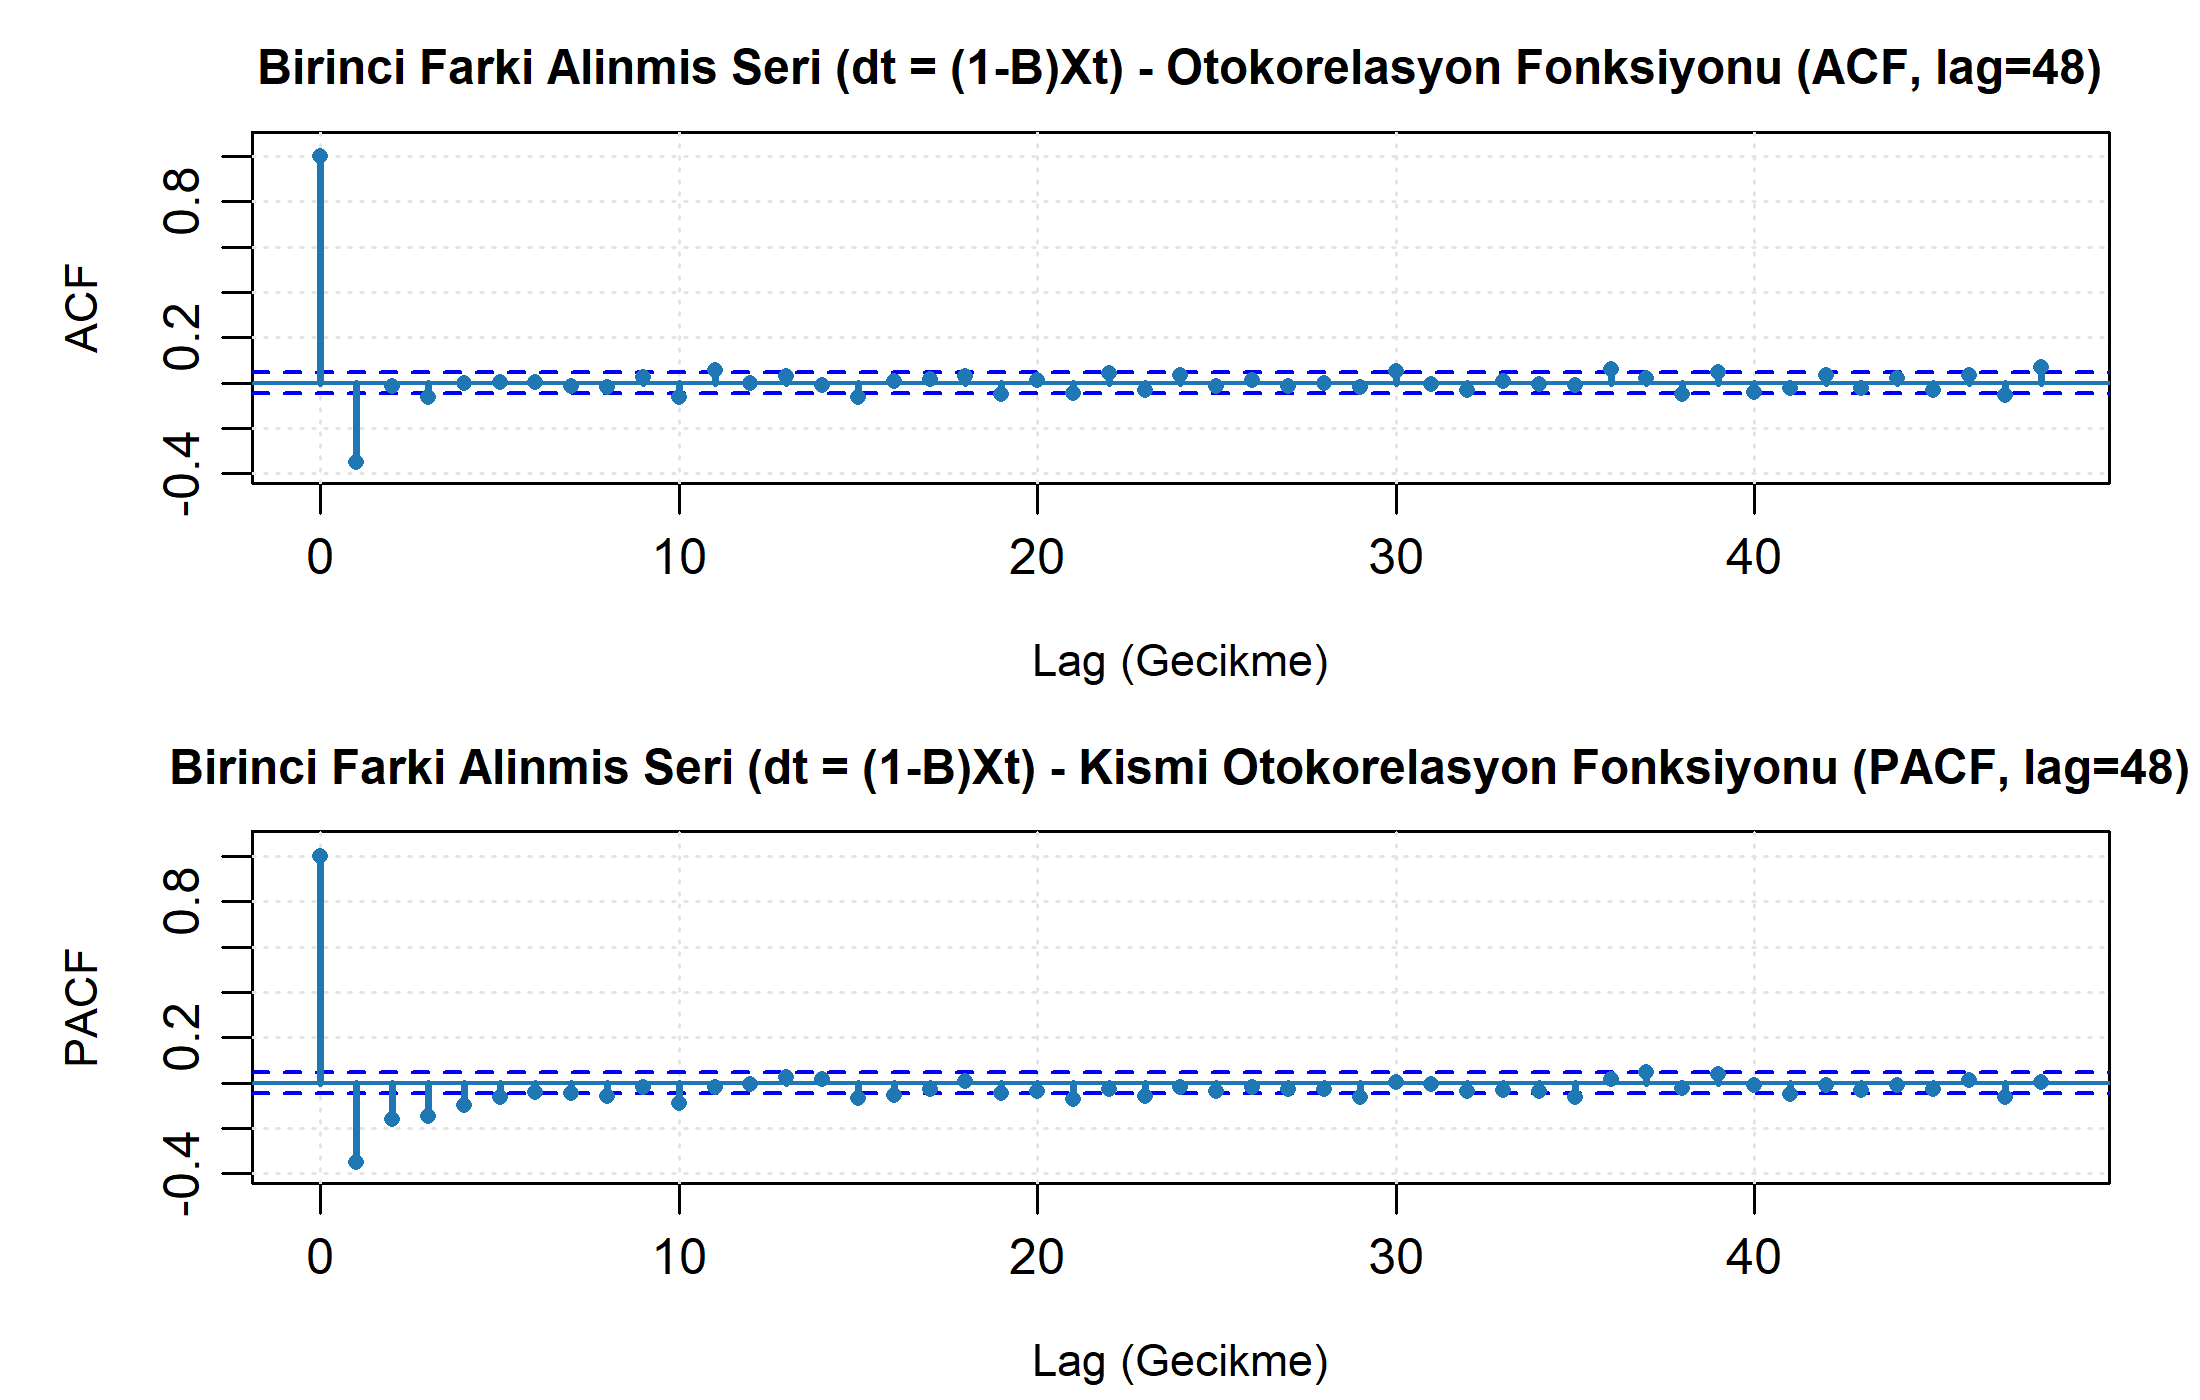

In [4]:
from statsmodels.tsa.stattools import acf, pacf  # r_k (ACF) ve r_kk (PACF) hesabı
from PythonTsa.plot_acf_pacf import acf_pacf_fig # Korelogram çizim fonksiyonu

# 1. Birinci fark serisinin (dt) sadece ACF (korelogram) grafiği (both=False)
acf_pacf_fig(dt, both=False, lag=48)      # 48 gecikmeye kadar ACF grafiği çizer
plt.savefig('pyTSA_TemperatureSH_fig3-3.png', dpi=1200,
            bbox_inches='tight', transparent=True, legend=None)
plt.show()                                # Grafiği ekranda gösterir

# 2. Orijinal serinin (temts) ACF ve PACF (KOK) grafiğini birlikte çizer
acf_pacf_fig(temts, both=True, lag=48)    # both=True: üstte ACF, altta PACF
plt.show()                                # Orijinal seri korelogramını gösterir

# 3. Birinci fark serisinin (dt) ACF ve PACF (KOK) grafiğini birlikte çizer
acf_pacf_fig(dt, both=True, lag=48)       # 1. farkın ACF ve PACF grafikleri
plt.show()                                # 1. fark korelogramını gösterir

# 4. Otokorelasyon (r_k) ve Kısmi Otokorelasyon (r_kk) Önemlilik Testleri
# H0: rho_k = 0 vs Ha: rho_k != 0 -> Test istatistiği: t = r_k / S_{r_k}
r_k = acf(dt, nlags=12, fft=False)[1:]    # 1. fark serisi r_k = gamma_k / gamma_0
r_kk = pacf(dt, nlags=12, method='ywm')[1:] # 1. fark serisi KOK (r_kk) değerleri
T = len(dt)                               # Gözlem sayısı (T = 1895)

# Bartlett Testi: S_{r_k}^2 = (1/T) * [1 + 2 * Sum_{i=1}^{k-1} r_i^2]
s_bart = [np.sqrt((1 + 2*np.sum(r_k[:k]**2))/T) for k in range(12)]
t_bart = r_k / np.array(s_bart)           # Bartlett t = r_k / S_{r_k}

# Moran Testi (SPSS): S_{r_k}^2 = (T - k) / [T * (T + 2)]
s_moran = [np.sqrt((T - k) / (T * (T + 2))) for k in range(1, 13)]
t_moran = r_k / np.array(s_moran)         # Moran t = r_k / S_{r_k}

# Kısmi Otokorelasyon (PACF) Önemlilik Testi: t = r_kk / (1 / sqrt(T))
t_pacf = r_kk / (1 / np.sqrt(T))          # |t| > 1.96 ise H0: rho_kk = 0 red

### 4.2 Yorum (ACF ve PACF Grafikleri)
* **1) Orijinal Serinin ($Z_t$) ACF ve PACF Yorumu (Trende Sahip Serinin ACF Yapısı):** Orijinal serinin ACF grafiği incelendiğinde, otokorelasyon katsayılarının ($r_1 = 0.8965, r_2 = 0.8654, \dots, r_{12} = 0.7324$) 48 gecikme boyunca mavi kesikli güven sınırlarını ($\mp t_{\alpha/2}S_{r_k} = \pm 0.0450$) fazlasıyla aştığı ve oldukça yüksek değerlere sahip olduğu görülmektedir. Birbirine yakın gözlemler arasında yüksek bir ilişki vardır ve gecikme sayısı $k$ arttıkça otokorelasyon katsayılarında **doğrusal olarak çok yavaş bir azalma** izlenmektedir. ACF grafiğindeki bu yavaş azalış serinin **güçlü bir trende sahip olduğunun ve durağan olmadığının** tipik göstergesidir. Ayrıca $k = 12, 24, 36, 48$ gecikmelerinde belirgin bir periyodik sıçrama olmadığı için seride mevsimsel dalgalanma yoktur.
* **2) 1. Fark Serisinin ($\Delta Z_t$) ACF ve PACF Önemlilik Testi Yorumu:** Birinci fark alındıktan sonra çizilen ACF grafiğinde trend kaynaklı yavaş azalma tamamen ortadan kalkmıştır. $H_0: \rho_k = 0$ hipotezi **Bartlett Testi** ve **Moran Testi** ile test edildiğinde, **1. gecikmede çok güçlü ve istatistiksel olarak önemli negatif bir otokorelasyon ($r_1 = -0.3523$, Bartlett $t = -15.34$, Moran $t = -15.35$; $|t| > 1.96 \rightarrow H_0$ red)** bulunmaktadır. $k \ge 2$ olan gecikmelerde ise ACF değerleri ($r_2 = -0.0159, t = -0.62$) sıfıra çok yakın olup güven sınırları içinde kalmaktadır.
* **3) PACF (Kısmi Otokorelasyon / KOK) Yorumu:** 1. fark serisinin PACF ($r_{kk}$) grafiğinde ise $t = r_{kk} / (1/\sqrt{T})$ testi sonucunda ilk 5 gecikmenin ($r_{11} = -0.3523, r_{22} = -0.1599, r_{33} = -0.1476, r_{44} = -0.0997, r_{55} = -0.0624$) negatif bölgede kademeli olarak azalarak sıfıra yaklaştığı görülmektedir.

---
## 5. Durağanlığın İncelenmesi
### 5.1 Python Kodu ve Çıktısı

=== 1. Fark Serisi Portmanteau (Ljung-Box Q* ve Box-Pierce Q) Testi ===
         lb_stat     lb_pvalue     bp_stat     bp_pvalue
6     243.692614  1.008498e-49  243.293275  1.224815e-49
12    259.317782  6.208152e-49  258.831342  7.839015e-49
24    287.274713  8.452130e-47  286.469411  1.213095e-46

=== Birim Kök Testi (ADF) Sonuçları ===
ADF Orijinal Seri (Z_t)     : t = -2.2437, p = 0.1908 (> 0.05 -> Durağan Değil)
ADF 1. Fark Serisi (Delta Z): t = -13.5343, p = 2.5862e-25 (< 0.05 -> DURAĞAN)

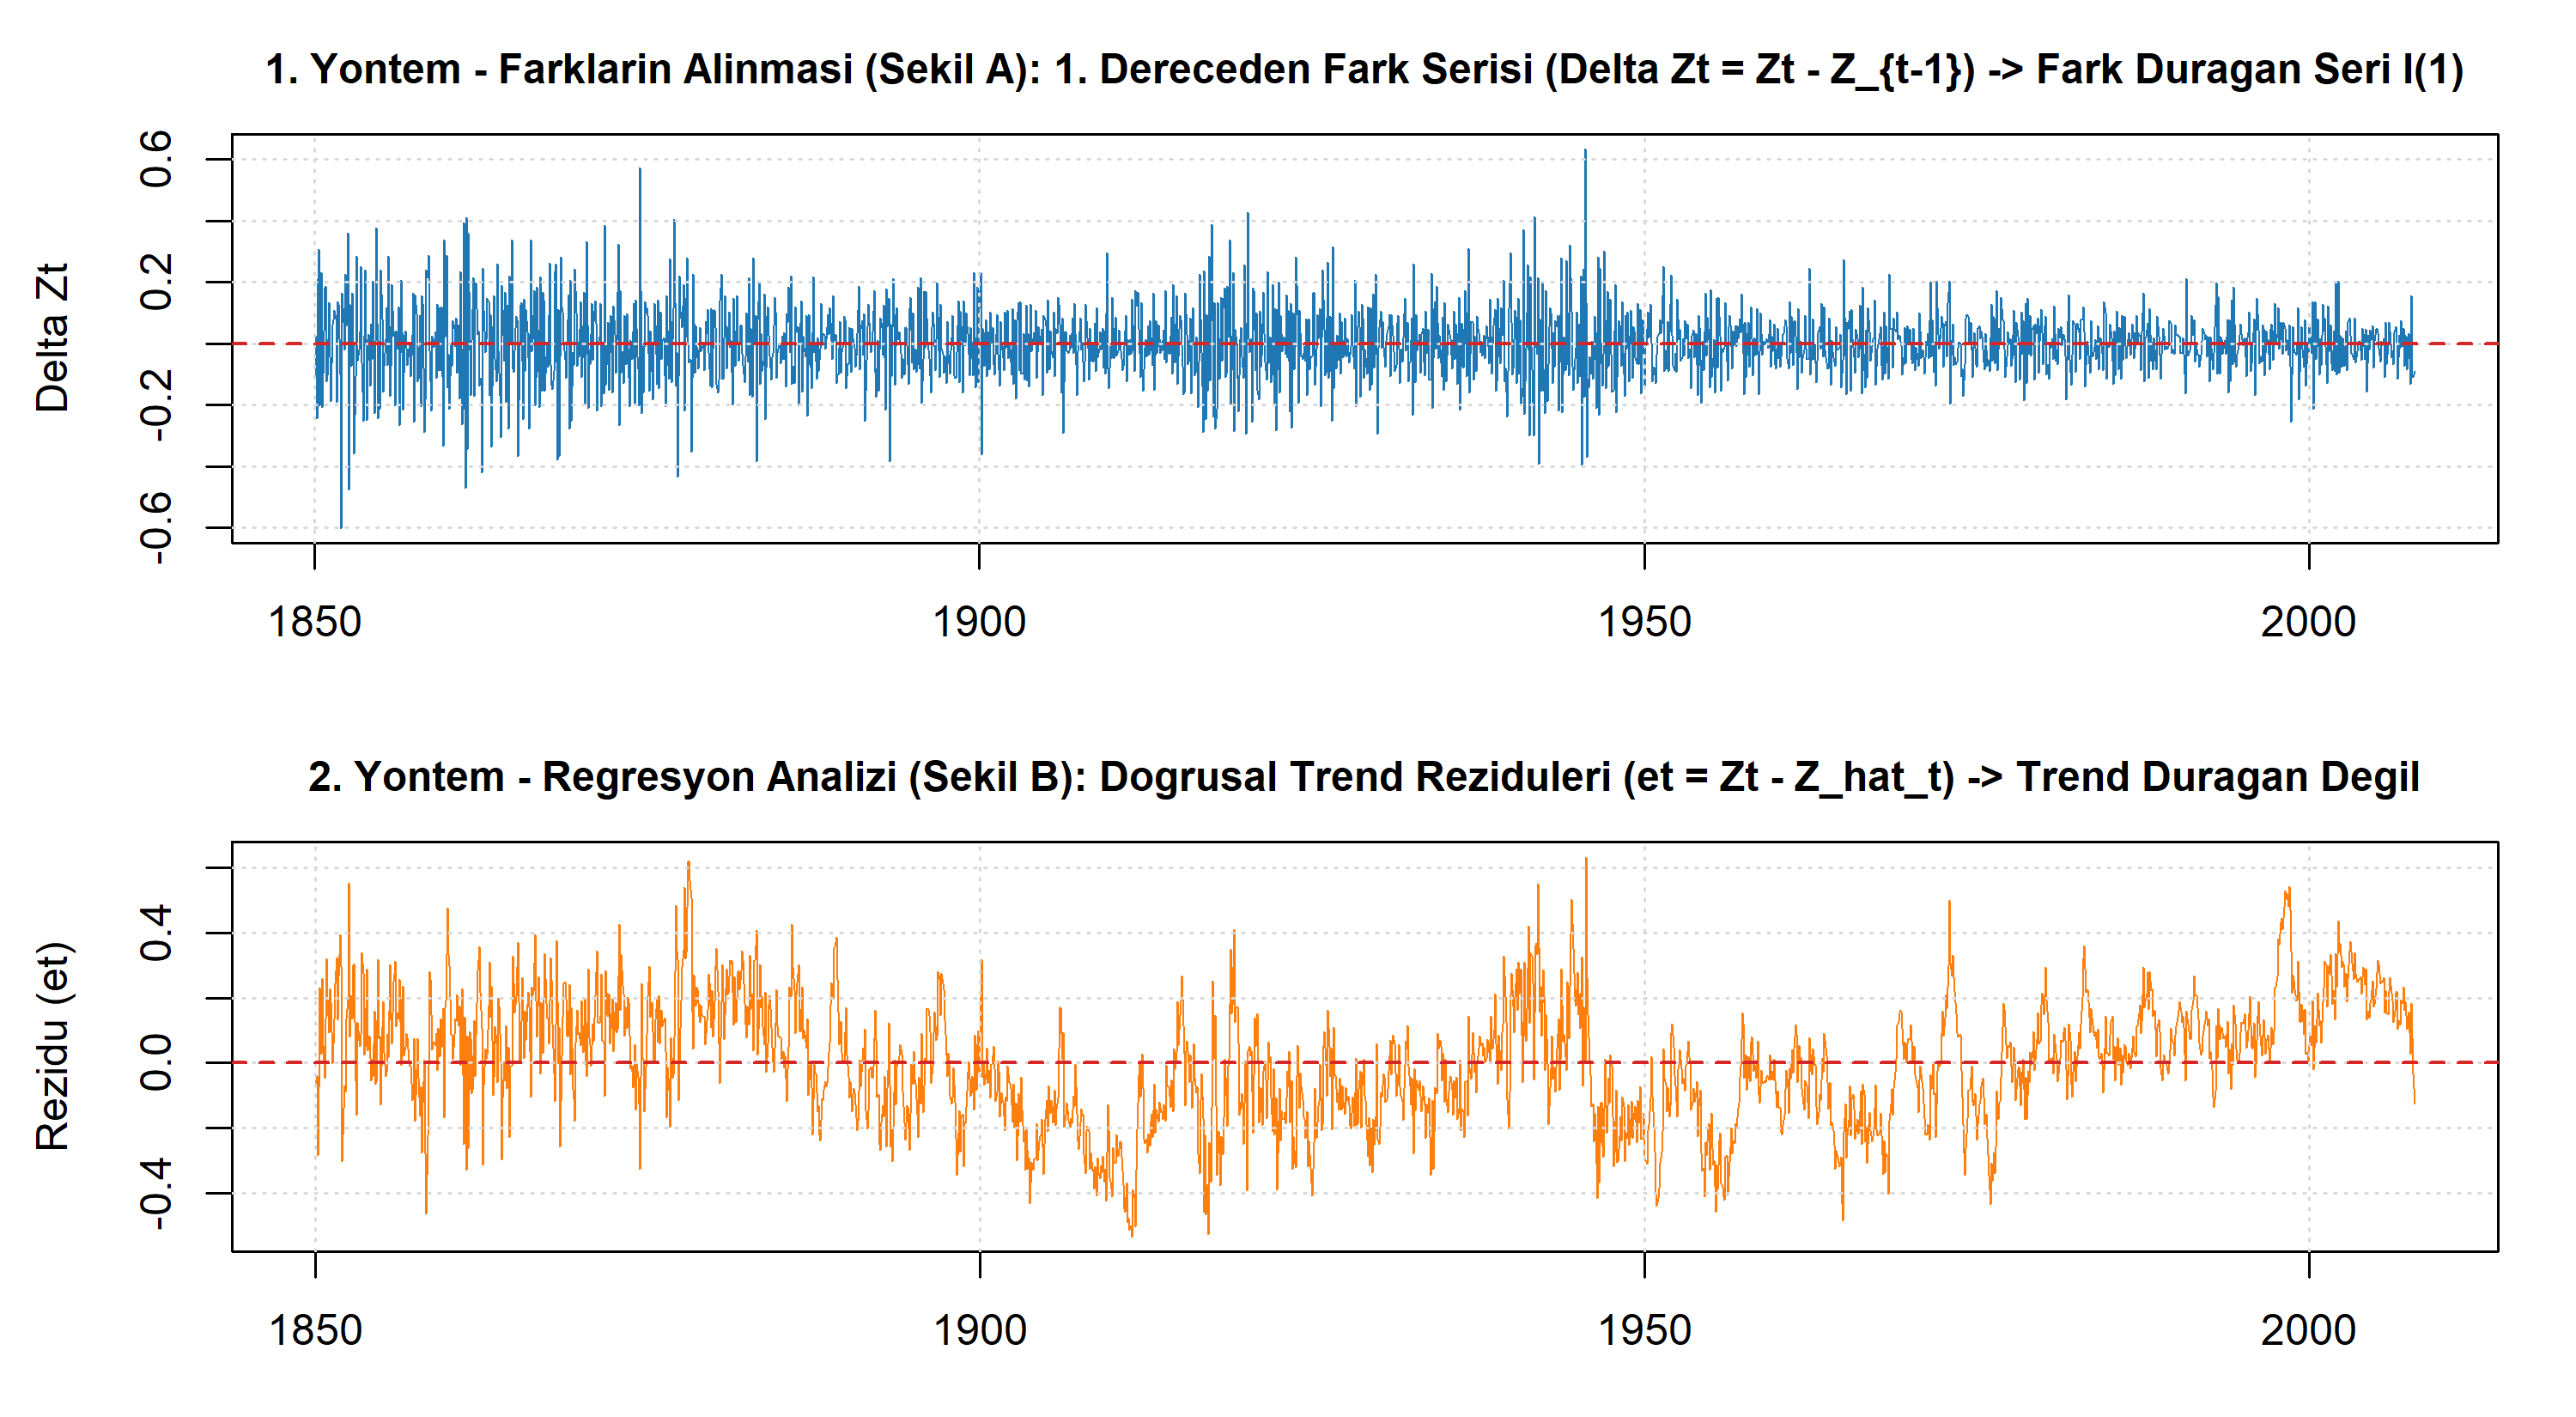

In [5]:
from statsmodels.stats.diagnostic import acorr_ljungbox # Box-Pierce ve Ljung-Box
from statsmodels.tsa.stattools import adfuller          # Birim kök testi (ADF)
import statsmodels.api as sm                            # Regresyon analizi (OLS)

# 1. Portmanteau Testleri (Q İstatistikleri): Box-Pierce (Q) ve Ljung-Box (Q*)
# H0: rho_1 = rho_2 = ... = rho_k = 0 vs Ha: En az bir rho_j != 0
lb_orig = acorr_ljungbox(temts, lags=[6, 12, 24], boxpierce=True) # Z_t için Q
lb_dt = acorr_ljungbox(dt, lags=[6, 12, 24], boxpierce=True)      # Delta Z_t için Q
print('=== 1. Fark Serisi Portmanteau (Ljung-Box & Box-Pierce) Testi ===')
print(lb_dt[['lb_stat', 'lb_pvalue', 'bp_stat', 'bp_pvalue']])

# 2. Birim Kök Testi (ADF): H0: Seride birim kök vardır (Durağan değildir)
adf_orig = adfuller(temts, regression='c', autolag='AIC') # Orijinal seri (Z_t)
adf_dt = adfuller(dt, regression='c', autolag='AIC')      # 1. fark (Delta Z_t)
print(f'ADF Orijinal Seri (Z_t)     : t = {adf_orig[0]:.4f}, p = {adf_orig[1]:.4f}')
print(f'ADF 1. Fark Serisi (Delta Z): t = {adf_dt[0]:.4f}, p = {adf_dt[1]:.4e}')

# 3. Durağanlaştırma: (1) Farkların Alınması vs (2) Regresyon Analizi
t_idx = np.arange(1, len(temts) + 1)      # Zaman değişkeni: t = 1, 2, ..., 1896
ols_fit = sm.OLS(temts.values, sm.add_constant(t_idx)).fit() # Z_hat_t = b0 + b1*t
resid_e = temts.values - ols_fit.fittedvalues # Rezidü serisi: e_t = Z_t - Z_hat_t

### 5.2 Yorum (Durağanlığın İncelenmesi ve Genel Sonuç)

| İncelenen Kriter / Test | Orijinal Seri ($Z_t$ — Şekil 3.1) | 1. Dereceden Fark Serisi ($\Delta Z_t = Z_t - Z_{t-1}$) |
| :--- | :--- | :--- |
| **1. Beklenen Değer / Ortalama Koşulu** ($E(Z_t) = \mu$) | Artan trend var, ortalama sabit değil ($\bar{Z} = -0.2216$) $\rightarrow$ **Sağlanmıyor** | Trend yok edildi, ortalama $0$ etrafında sabit ($\overline{\Delta Z} = 0.000324 \approx 0$) $\rightarrow$ **Sağlanıyor** |
| **2. Varyans Homojenliği Koşulu** ($\text{Var}(Z_t) = \sigma^2$) | Trend nedeniyle toplam yayılım yüksek ($\hat{\gamma}_0 = 0.07325$) | Belirli ortalama etrafında yaklaşık sabit sıçramalı varyans ($\hat{\gamma}_0 = 0.01506$) $\rightarrow$ **Sağlanıyor** |
| **3. Otokovaryans ve ACF Korelogramı** ($\text{Cov}(Z_t, Z_{t+k}) = \gamma_k$) | Tüm gecikmelerde güven sınırları ($\pm 0.0450$) aşılıyor, ACF çok yavaş azalıyor $\rightarrow$ **Durağan Değil** | Sadece $k=1$ önemli ($r_1 = -0.3523$), $k \ge 2$ için ilişkiler güven sınırları içinde $\rightarrow$ **Durağan** |
| **4. Portmanteau Testleri ($k=12$)** (Box-Pierce $Q$ ve Ljung-Box $Q^*$, $\chi^2_{0.05,12}=21.03$) | $Q = 14418.36$, $Q^* = 14480.00$ ($p < 0.001$) $\rightarrow$ Güçlü trend bağımlılığı var | $Q = 258.83$, $Q^* = 259.32$ ($p < 0.001$) $\rightarrow$ Durağan ama $r_1 = -0.3523$ nedeniyle **Ak Gürültü Değil** |
| **5. Birim Kök Testi (ADF)** ($\%5$ Kritik Değer $= -2.8631$) | $t = -2.2437 > -2.8631$ ($p = 0.1908 > 0.05$) $\rightarrow$ $H_0$ Kabul (**Birim Kök Var / Durağan Değil**) | $t = -13.5343 < -2.8631$ ($p < 0.0001$) $\rightarrow$ $H_0$ Red (**Birim Kök Yok / DURAĞAN**) |

1. **Zaman Serisi Grafiği ve Zayıf Durağanlığın 3 Koşulu:** Bir zaman serisinin zayıf durağan olması için beklenen değerinin sabit ($E(Z_t) = \mu$), varyansının sabit ($\text{Var}(Z_t) = \sigma^2$) ve otokovaryansının zamandan bağımsız, sadece gecikme sayısı $k$'ya bağlı ($\text{Cov}(Z_t, Z_{t+k}) = \gamma_k$) olması gerekir. Şekil 3.1'deki orijinal seride belirgin bir artan trend bulunduğundan **ortalama sabit değildir ve orijinal seri durağan değildir**.
2. **ACF Grafiği ve Birim Kök Testi ile İnceleme:** Durağan bir seride ACF grafiğindeki ilişkilerin güven sınırları ($\mp t_{\alpha/2}S_{r_k} = \pm 0.0450$) içinde kalması gerekirken, orijinal serinin ACF grafiğinde tüm gecikmeler güven sınırlarını aşmakta ve yavaşça azalmaktadır. Birim kök testi (ADF) de orijinal seride birim kök bulunduğunu ($t = -2.2437, p = 0.1908 > 0.05$) doğrulamaktadır.
3. **Farkların Alınması ve Fark Durağan Seri — $I(1)$ (Şekil A vs Şekil B):** Durağan olmayan bir seriyi durağanlaştırmak için uygulanan iki yöntemden ilki olan **Farkların Alınması** uygulandığında, serinin **1. dereceden farkı ($\Delta Z_t = Z_t - Z_{t-1}$)** belirli bir ortalama ($0$) etrafında yaklaşık sabit sıçramalı bir varyans ($\hat{\gamma}_0 = 0.01506$) göstermektedir. Fark serisinin ACF grafiğinde $k=1$ dışındaki tüm gecikmeler güven sınırları içerisine girmiş ve birim kök testi ($t = -13.5343, p < 0.0001$) serinin durağanlaştığını kanıtlamıştır. Buna karşılık ikinci yöntem olan doğrusal regresyon analizinde (Şekil B) rezidüler ($e_t = Z_t - \hat{Z}_t$) hâlâ dalgalanma ve yüksek otokorelasyon sergilemektedir.
4. **Ak Gürültü Kontrolü (Portmanteau Box-Pierce ve Ljung-Box Testleri):** $\Delta Z_t$ fark serisi durağandır; ancak 1. gecikmedeki otokorelasyon ($r_1 = -0.3523$) güven sınırını aştığı ve Box-Pierce ($Q = 258.83 > 21.03$) ile Ljung-Box ($Q^* = 259.32 > 21.03$) testlerinde $H_0$ reddedildiği için fark serisi **ak gürültü (beyaz gürültü) seri değildir** (*"Her ak gürültü seri durağandır, fakat her durağan seri ak gürültü değildir"*). Sonuç olarak Şekil 3.1'deki Güney Yarımküre sıcaklık serisi, 1 kez farkı alındığında durağan hâle geldiği için **fark durağan seri (1. dereceden bütünleşik seri — $I(1)$)** yapısındadır ve Box-Jenkins (ARIMA) modelleriyle analiz edilmeye uygundur.